# Flux: GPP and RECO of the LI-7500 years compared with the LI-7200 years

# About this notebook

The open-path LI-7500 (`IRGA75`) years of this product are close to neutral or a source of CO2 in
2004-2009 and a moderate sink from 2010, while the enclosed-path LI-7200 (`IRGA72`) years
2016-2025 are a sink on average. Two earlier checks narrow the cause down: winter and summer
nighttime `NEE` of the LI-7500 years agree with the LI-7200 years, and summer daytime `NEE` at the
same light and air temperature has less uptake in 2005-2007 than in the LI-7200 years (see
`OPCO_TRANSFER_CHECK_2004-2017` in `30_FLUX_POST-PROCESSING_CHAIN/IRGA75`).

This notebook asks which flux component, gross primary production (`GPP`) or ecosystem
respiration (`RECO`), and which months and conditions make the early years less of a sink. It
compares the two analyser periods by:

1. annual and monthly `GPP`, `RECO` and `NEE` from the nighttime and the daytime partitioning, and
   the monthly parts of the difference in annual `NEE`;
2. the light response of `GPP` and the temperature response of `RECO` under matched conditions,
   the fitted parameters of both partitioning methods, and a split of the difference in annual
   `GPP` into a peak-capacity part and a season-length part;
3. the timing of the growing season: the spring and autumn compensation points of `NEE`, the
   period of high `GPP`, and the spring rise of the canopy albedo;
4. the weather of each year;
5. a summary of the difference in `NEE` of the early years, split into seasons, into day and
   night, and into `GPP` and `RECO`.

It computes no product.

**Which run is shown.** The notebook reads the outputs of the flux chain as they are on disk, so a
rerun of the chain refreshes every number below. The modification time of each input file is
printed under *Load data*; the numbers belong to the run of that date.

**Partitioning is not an independent measurement.** Both methods split the same gap-filled `NEE`
of this product, after its self-heating correction (Level 1.1). A bias of the measured `NEE`
therefore reappears as a change of `GPP` or `RECO`: the nighttime method extrapolates `RECO`
from the nights into the day and assigns every daytime difference to `GPP`; the daytime method
fits light and temperature responses to the daytime data and can assign it to either. The split
says where a difference sits in the flux, not whether the difference is real.

**Sign convention and units.** `NEE` is negative when the forest takes up CO2; `GPP` and `RECO`
are positive. Half-hourly values are in µmol CO2 m⁻² s⁻¹; sums are in gC m⁻² (1 µmol m⁻² s⁻¹ over
30 minutes is 0.0216 gC m⁻²). In the tables of differences a part is stated as its contribution
to the difference in `NEE`, so the parts add up: `ΔNEE = ΔRECO − ΔGPP`. A positive value means
less uptake than in the LI-7200 years.

**Columns used**

- `NEE` of this product, both analysers (`30_FLUX_POST-PROCESSING_CHAIN/IRGA75/05_FPPC_IRGA75_NEE_OPCO_2004-2017`
  and `.../IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09`):
  - `NEE_L3.1_L3.3_CUT_50_QCF_gfXG` — `NEE` after all quality tests, filtered at the median USTAR
    threshold (`CUT_50`) and gap-filled with XGBoost
  - `NEE_L3.1_L3.3_CUT_50_QCF` — the same before gap-filling, the measured records
  - `DAYTIME`, `NIGHTTIME` — the day and night flags of this product
- Nighttime partitioning (Reichstein et al. 2005, as in ONEFlux): `GPP_NT_OF_CUT_50`,
  `RECO_NT_OF_CUT_50`, the reference respiration at 15 °C `RREF_NT_OF_CUT_50` (interpolated to
  every record) and the temperature sensitivity `E0_NT_OF_CUT_50` (K, one value per year)
- Daytime partitioning (Lasslop et al. 2010, as in ONEFlux): `GPP_DT_OF_CUT_50`,
  `RECO_DT_OF_CUT_50`, and the parameters of each fitting window: `ALPHA_DT_OF_CUT_50` (initial
  slope of the light response, µmol J⁻¹), `BETA_DT_OF_CUT_50` (`GPP` at light saturation,
  µmol m⁻² s⁻¹), `K_DT_OF_CUT_50` (VPD sensitivity), `RREF_DT_OF_CUT_50`, `E0_DT_OF_CUT_50`
- Meteo (`10_METEO/30_PRODUCTS/99_METEO_MERGED_2004-2026.09`), at 47 m unless stated: air
  temperature `TA_T1_47_1_HOMOGENIZED_gfXG`, `SW_IN_T1_47_1_gfXG` and `PPFD_IN_T1_47_1_gfXG` with
  their fill flags, `VPD_T1_47_1_HOMOGENIZED`, precipitation `PREC_TOT_T1_47_1_HOMOGENIZED`, soil
  water content at 0.1 and 0.3 m `SWC_FF1_0.1_1_HOMOGENIZED`, `SWC_FF1_0.3_1_HOMOGENIZED`, and
  the reflected shortwave radiation `SW_OUT_T1_47_1` with its instrument flag

**Periods.** The LI-7500 years are 2004-2015, the years in which it is the only analyser of this
product; the reference is the LI-7200 in 2016-2025. The LI-7500 years are grouped as 2005-2007
(the summers with the largest daytime deficit), 2008-2009 (the other years of Etzold et al. 2011)
and 2010-2015. 2004 is shown per year but is in no group: it is measured from 31 March, and no
shortwave radiation was measured.

**The daytime method before September 2005.** `SW_IN` was measured from 14 September 2005; the
daytime method has no measured light to fit before, and `IRGA75/05` leaves its results empty
until then. 2004 and 2005 therefore have no annual daytime sum, and group means of the daytime
method use the complete years only (2006-2007 in the group 2005-2007).

# Main findings

The numbers behind each point are in the tables below.

- **Day, not night.** Nearly all of the difference in annual `NEE` between the early LI-7500
  years and the LI-7200 years lies in the daytime half-hours. The nighttime half-hours differ
  little, and in the opposite direction.
- **GPP in the nighttime method.** The nighttime method assigns the difference to lower `GPP`. Its
  `RECO` of the early years is close to that of the LI-7200 years in the annual sum, per month and
  at the same night temperature. This follows from the first point, since the method extrapolates
  respiration from the nights into the day.
- **The daytime method carries an offset between the analyser periods.** It gives lower `GPP` and
  lower `RECO` in every LI-7500 year, 2010-2015 included, whose `NEE` agrees with the LI-7200
  years. Against 2010-2015, the same analyser, it splits the additional deficit of 2005-2009 about
  evenly between lower `GPP` and higher `RECO`. The split into the two components is therefore
  not robust; its location in the daytime flux is.
- **Months.** In 2005-2007 the difference lies in the growing season, mostly in June and July and
  in April and September; the winter contributes little. In 2008-2009 it is spread over the year,
  with similar shares from the daytime of January to April, from April and October, and from the
  summer.
- **Capacity, not season length.** At matched light and air temperature, peak-season `GPP` of the
  early years is lower, most at high light and at air temperatures below 20 °C, and most in 2005
  and 2006. The peak capacity of `GPP` is lower; the effective season length is not shorter. The
  carbon uptake period starts later and ends earlier, but the spring rise of the canopy albedo
  and of `GPP` are not later: net uptake starts later because spring uptake is smaller, not
  because leaf-out is later.
- **Weather.** 2004-2010 were cooler and had less summer radiation than the LI-7200 years, and the
  summer soils of 2004-2006 were drier. 2010-2015 had similar weather and agree with the LI-7200
  years. Against the weather of each summer, 2004-2006 stand out with low `GPP`, also against the
  dry LI-7200 summers 2018 and 2022; 2007-2009 lie within the spread of the other years.
- **What this implies.** A reduced canopy capacity in 2004-2006, with dry soils in the years after
  the drought of 2003, is consistent with these data. A daytime bias of the LI-7500 flux in the
  same years, such as a too large self-heating correction, produces the same pattern, and the
  partitioning cannot tell the two apart. The winter and spring daytime share of 2008-2009 lies
  where the correction is large relative to the flux.

</br>

# Settings

In [1]:
# This product. The flux chain's outputs are read as they are on disk, so a rerun of the chain
# refreshes every number in this notebook.
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
FILE_NEE75 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet"
FILE_NEE72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"
FILE_METEO = r"10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"

# Flux columns of both analysers and the short names used below.
FLUX_COLS = {
    'NEE_L3.1_L3.3_CUT_50_QCF_gfXG': 'nee',  # the main series, gap-filled
    'NEE_L3.1_L3.3_CUT_50_QCF': 'nee_meas',  # measured records that pass all tests
    'GPP_NT_OF_CUT_50': 'gpp_nt', 'RECO_NT_OF_CUT_50': 'reco_nt',
    'RREF_NT_OF_CUT_50': 'rref_nt', 'E0_NT_OF_CUT_50': 'e0_nt',
    'GPP_DT_OF_CUT_50': 'gpp_dt', 'RECO_DT_OF_CUT_50': 'reco_dt',
    'ALPHA_DT_OF_CUT_50': 'alpha', 'BETA_DT_OF_CUT_50': 'beta', 'K_DT_OF_CUT_50': 'k',
    'RREF_DT_OF_CUT_50': 'rref_dt', 'E0_DT_OF_CUT_50': 'e0_dt',
    'DAYTIME': 'daytime', 'NIGHTTIME': 'nighttime',
}
DT_COLS = ['gpp_dt', 'reco_dt', 'alpha', 'beta', 'k', 'rref_dt', 'e0_dt']
# Meteo products. A fill flag of 0 marks a measured value.
METEO_COLS = {
    'TA_T1_47_1_HOMOGENIZED_gfXG': 'ta',  # degC, complete
    'SW_IN_T1_47_1_gfXG': 'sw', 'FLAG_SW_IN_T1_47_1_ISFILLED': 'sw_flag',  # W m-2
    'PPFD_IN_T1_47_1_gfXG': 'ppfd', 'FLAG_PPFD_IN_T1_47_1_ISFILLED': 'ppfd_flag',  # umol m-2 s-1
    'VPD_T1_47_1_HOMOGENIZED': 'vpd',  # kPa
    'PREC_TOT_T1_47_1_HOMOGENIZED': 'prec',  # mm per half-hour
    'SWC_FF1_0.1_1_HOMOGENIZED': 'swc10', 'SWC_FF1_0.3_1_HOMOGENIZED': 'swc30',  # % VWC
    'SW_OUT_T1_47_1': 'sw_out', 'FLAG_SW_OUT_T1_47_1_INSTRUMENT': 'sw_out_instr',  # W m-2
}

# Periods.
IRGA75_YEARS = (2004, 2015)  # the LI-7500 is the only analyser of this product
IRGA72_YEARS = (2016, 2025)  # full LI-7200 years, the reference
REF = 'IRGA72 2016-2025'
GROUPS = {'2005-2007': (2005, 2007), '2008-2009': (2008, 2009), '2010-2015': (2010, 2015),
          REF: IRGA72_YEARS}
EARLY_GROUPS = [g for g in GROUPS if g != REF]
SUMMARY_GROUPS = {'2005-2007': (2005, 2007), '2008-2009': (2008, 2009), '2005-2009': (2005, 2009),
                  '2010-2015': (2010, 2015)}
DT_VALID_FROM = '2005-09-14 11:15'  # first measured SW_IN; IRGA75/05 leaves the daytime method empty before it
FIRST_LIGHT_YEAR = 2005  # first year with measured PPFD in summer
SEASONS = {'Nov-Mar': [11, 12, 1, 2, 3], 'Apr+Oct': [4, 10], 'May-Sep': [5, 6, 7, 8, 9]}
PEAK = [6, 7, 8]  # the peak season, for the light response and the parameters
SUMMER = [5, 6, 7, 8, 9]  # the summer of the weather table
LT_TREF, LT_T0 = 15.0, -46.02  # degC, Lloyd & Taylor reference temperatures of ONEFlux

# Matched conditions.
DAY_PPFD = 20  # umol m-2 s-1: daytime in the light-response comparisons (measured PPFD above it)
PPFD_BINS = [20, 200, 400, 600, 800, 1000, 1200, 1500, 2500]  # umol m-2 s-1
TA_BINS = [-10, 14, 18, 22, 26, 40]  # degC, cells of the standardisation by day
TA_PANELS = [-10, 16, 20, 24, 40]  # degC, panels of the light-response plot
HIGH_PPFD = 1000  # umol m-2 s-1: high light, for the light-saturated GPP
NIGHT_TA_BINS = [-5, 8, 10, 12, 14, 16, 18, 20, 22, 35]  # degC, summer nights
MIN_CELL_N = 10  # fewest records for a cell mean to enter a standardised mean

# Season timing.
SMOOTH_DAYS = 15  # days of the centred running mean of daily NEE and GPP
PERSIST_DAYS = 10  # smoothed NEE must stay negative this many days to start or end the uptake
SPRING_FROM_DOY = 60  # the spring search starts on 1 March
GPP_FRACTION = 0.5  # GPP season: smoothed daily GPP at or above this fraction of its peak
ALBEDO_HOURS = (10, 14)  # hours of the midday albedo, from and before
ALBEDO_MIN_SW = 50  # W m-2: half-hours with less SW_IN are left out of the albedo
ALBEDO_MIN_RECORDS = 6  # fewest midday half-hours for a daily albedo
ALBEDO_SMOOTH = 7  # days of the centred running median of the daily albedo
ALBEDO_MIN_WINDOW = (80, 125)  # DOY window of the spring minimum of the albedo, after most snow
ALBEDO_PERSIST = 10  # days the smoothed albedo must stay above the midpoint
ALBEDO_SUMMER_WINDOW = (160, 200)  # DOY window of the summer level of the albedo
GDD_BASE, GDD_END_DOY = 5.0, 120  # growing degree days above 5 degC from 1 January to 30 April

units = "µmol m-2 s-1"
units_sum = "gC m-2"
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # umol CO2 m-2 s-1 over one half-hour -> gC m-2
COLORS = {'2005-2007': '#E53935', '2008-2009': '#FB8C00', '2010-2015': '#1E88E5', REF: '#43A047',
          'gpp': '#00897B', 'reco': '#8D6E63', 'nee': '#212121', 'rest': '#BDBDBD'}

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
version_diive = importlib.metadata.version("diive")
print(f"diive version: v{version_diive}")

diive version: v0.93.0


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.0f}", subset=None, cmap="RdBu_r", axis=None, center=True):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table. `center` puts the midpoint of the colour scale at
    zero; `axis=None` scales the colours across the whole table (or `subset`). The colour scale
    sets a text colour per cell, so the numbers stay readable in light and dark pages.
    """
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        if isinstance(subset, tuple):
            values = data.loc[subset]
        else:
            values = data[subset] if subset is not None else data[numeric]
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def years_of(group):
    """The calendar years of a group, as a list."""
    y0, y1 = (SUMMARY_GROUPS | GROUPS)[group]
    return list(range(y0, y1 + 1))


def group_of(year):
    """The group of GROUPS a year belongs to, or None."""
    for g, (y0, y1) in GROUPS.items():
        if y0 <= year <= y1:
            return g
    return None


def month_axis(ax):
    """Month names on an axis of calendar months 1-12."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([calendar.month_abbr[m] for m in range(1, 13)])
    return ax


def lloyd_taylor(ta, rref, e0):
    """Respiration of Lloyd & Taylor (1994) at air temperature `ta` (degC), as in ONEFlux."""
    return rref * np.exp(e0 * (1 / (LT_TREF - LT_T0) - 1 / (ta - LT_T0)))


def cells(d, xcol, xbins, ycol, ybins):
    """Bin keys of two drivers, for groupby."""
    return [pd.cut(d[xcol], xbins), pd.cut(d[ycol], ybins)]


def std_mean(d, weights, keys, col):
    """Mean of `col` over cells, weighted by a fixed distribution of the cells.

    Cells with fewer than MIN_CELL_N records drop out. Returns the standardised mean and the
    share of the weight that is covered.
    """
    g = d.groupby(keys, observed=True)[col]
    m = g.mean()[g.size() >= MIN_CELL_N].dropna()
    w = weights.reindex(m.index).fillna(0)
    cover = w.sum()
    return pd.Series({'mean': (m * w).sum() / cover if cover > 0 else np.nan, 'cover': cover})


def ref_band(ax, values, color=COLORS[REF], label=True):
    """Shade the mean ± one standard deviation of the IRGA72 years on an axis."""
    v = values.loc[IRGA72_YEARS[0]:IRGA72_YEARS[1]].dropna()
    ax.axhspan(v.mean() - v.std(), v.mean() + v.std(), color=color, alpha=0.12, lw=0,
               label="IRGA72 2016-2025, mean ± sd" if label else None)
    ax.axhline(v.mean(), color=color, lw=1, ls=':')


def diff_to_ref(table, groups, sign=None):
    """Group means of a per-year table, their difference to the IRGA72 mean, and the IRGA72 sd.

    `sign` maps column names to -1 for the columns whose difference enters ΔNEE with a negative
    sign (GPP), so every difference column is a contribution to ΔNEE.
    """
    sign = sign or {}
    ref = table.loc[IRGA72_YEARS[0]:IRGA72_YEARS[1]]
    rows = {}
    for g in groups:
        sub = table.reindex(years_of(g))
        rows[g] = (sub.mean() - ref.mean()) * pd.Series({c: sign.get(c, 1) for c in table.columns})
    out = pd.DataFrame(rows).T
    out.loc['IRGA72 sd of years'] = ref.std()
    return out

</br>

# Load data

In [4]:
_files = {'this product, IRGA75 NEE (05)': Path(DATADIR) / FILE_NEE75,
          'this product, IRGA72 NEE (05)': Path(DATADIR) / FILE_NEE72,
          'meteo products (99)': Path(DATADIR) / FILE_METEO}

n75 = pd.read_parquet(_files['this product, IRGA75 NEE (05)'], columns=list(FLUX_COLS)).rename(columns=FLUX_COLS)
n72 = pd.read_parquet(_files['this product, IRGA72 NEE (05)'], columns=list(FLUX_COLS)).rename(columns=FLUX_COLS)
met = pd.read_parquet(_files['meteo products (99)'], columns=list(METEO_COLS)).rename(columns=METEO_COLS)
for _df in (n75, n72, met):
    _df.index = pd.DatetimeIndex(_df.index).as_unit('ns')
    _df.index.name = 'TIMESTAMP_MIDDLE'

## 📋 Table: input files and the run they come from

In [5]:
_inputs = pd.DataFrame({
    'file': [p.name for p in _files.values()],
    'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" for p in _files.values()],
    'records': [len(n75), len(n72), len(met)],
    'first': [str(d.index[0]) for d in (n75, n72, met)],
    'last': [str(d.index[-1]) for d in (n75, n72, met)],
}, index=list(_files))
display(styled(_inputs, caption="the input files with their modification time and period. The numbers "
                                "in this notebook belong to the runs of these dates",
               fmt="{:,.0f}", cmap=None))

Table — the input files with their modification time and period. The numbers in this notebook belong
to the runs of these dates



,file,modified,records,first,last
"this product, IRGA75 NEE (05)",05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet,2026-10-31 17:24,"245,472",2004-01-01 00:15:00,2017-12-31 23:45:00
"this product, IRGA72 NEE (05)",05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-10-31 16:47,"188,448",2016-01-01 00:15:00,2026-09-30 23:45:00
meteo products (99),99_METEO_MERGED_2004-2026.09.parquet,2026-10-29 21:02,"398,832",2004-01-01 00:15:00,2026-09-30 23:45:00


In [6]:
# One frame of both analyser periods: the LI-7500 2004-2015 and the LI-7200 2016-2025, with the
# meteo on the same half-hours.
F = pd.concat([n75.loc[str(IRGA75_YEARS[0]):str(IRGA75_YEARS[1])].assign(analyser='IRGA75'),
               n72.loc[str(IRGA72_YEARS[0]):str(IRGA72_YEARS[1])].assign(analyser='IRGA72')])
F = F.join(met)
# The daytime method has no measured light to fit before DT_VALID_FROM (see About).
F.loc[F.index < pd.Timestamp(DT_VALID_FROM), DT_COLS] = np.nan
F['year'] = F.index.year
F['month'] = F.index.month
F['doy'] = F.index.dayofyear
F['group'] = F['year'].map(group_of)
F['day'] = F['daytime'].eq(1)
F['meas'] = F['nee_meas'].notna()
F['ppfd_meas'] = F['ppfd_flag'].eq(0)
F['sw_meas'] = F['sw_flag'].eq(0)
F['nee_dt_model'] = F['reco_dt'] - F['gpp_dt']  # NEE as the daytime model describes it
F['dt_rest'] = F['nee'] - F['nee_dt_model']  # the part of NEE the daytime model leaves out
F['nee_day'] = F['nee'].where(F['day'], 0.0)
F['nee_night'] = F['nee'].where(~F['day'], 0.0)
print(f"frame: {F.index[0]} -> {F.index[-1]} ({len(F):,} records)")
print(F.groupby('analyser')['year'].agg(['min', 'max', 'size']))

frame: 2004-01-01 00:15:00 -> 2025-12-31 23:45:00 (385,728 records)
           min   max    size
analyser                    
IRGA72    2016  2025  175344
IRGA75    2004  2015  210384


## Integrity checks

In [7]:
# Everything below assumes complete 30MIN records without duplicates, a complete main series and
# nighttime partitioning, the closure of the nighttime partitioning (NEE = RECO - GPP), one E0 per
# year, a complete daytime partitioning from DT_VALID_FROM, and day and night flags that exclude
# each other.
_issues = []
for _name, _df in (('IRGA75 05', n75), ('IRGA72 05', n72), ('meteo', met)):
    if _df.index.duplicated().any():
        _issues.append(f"{_name}: duplicate timestamps")
    if not (_df.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
        _issues.append(f"{_name}: index gaps")
_expected = pd.date_range(f"{IRGA75_YEARS[0]}-01-01 00:15", f"{IRGA72_YEARS[1]}-12-31 23:45", freq='30min')
if not F.index.equals(_expected):
    _issues.append("the frame does not cover every half-hour of the period")
for _c in ('nee', 'gpp_nt', 'reco_nt', 'rref_nt', 'e0_nt', 'ta', 'sw', 'ppfd', 'vpd'):
    if F[_c].isna().any():
        _issues.append(f"{_c}: {int(F[_c].isna().sum())} missing values")
_dev_nt = (F['reco_nt'] - F['gpp_nt'] - F['nee']).abs().max()
if _dev_nt > 1e-3:
    _issues.append(f"nighttime partitioning does not close: max |RECO - GPP - NEE| = {_dev_nt:.3g}")
if not (F['daytime'] + F['nighttime']).eq(1).all():
    _issues.append("DAYTIME and NIGHTTIME are not complementary")
if F.groupby('year')['e0_nt'].nunique().gt(1).any():
    _issues.append("E0_NT has more than one value in a year")
_dt = F.loc[DT_VALID_FROM:, ['gpp_dt', 'reco_dt']]
if _dt.isna().any().any():
    _issues.append(f"daytime partitioning has {int(_dt.isna().any(axis=1).sum())} missing records "
                   f"from {DT_VALID_FROM}")
if not ((F['nee_meas'] - F['nee']).abs()[F['meas']] < 1e-6).all():
    _issues.append("the gap-filled series differs from the measured one on measured records")
print(f"nighttime partitioning: max |RECO - GPP - NEE| = {_dev_nt:.2g} {units}")
print(f"daytime partitioning: mean |NEE - (RECO - GPP)| = {F['dt_rest'].abs().mean():.2f} {units} "
      f"(the daytime method is a model of NEE and does not close)")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

nighttime partitioning: max |RECO - GPP - NEE| = 3.8e-06 µmol m-2 s-1
daytime partitioning: mean |NEE - (RECO - GPP)| = 3.44 µmol m-2 s-1 (the daytime method is a model of NEE and does not close)
Integrity checks passed.


</br>

# 1 Annual and monthly GPP and RECO

Annual sums per year from both partitioning methods. The nighttime method closes on `NEE` by
construction (`GPP = RECO − NEE`); the daytime method is a model of `NEE`, and the difference
between the gap-filled `NEE` and `RECO − GPP` of that model is shown as its *rest*.

## 📋 Table: annual sums per year

In [8]:
COMP = {'nee': 'NEE', 'gpp_nt': 'GPP (NT)', 'reco_nt': 'RECO (NT)', 'gpp_dt': 'GPP (DT)',
        'reco_dt': 'RECO (DT)', 'dt_rest': 'rest (DT)'}
_size = F.groupby('year').size()
annual = F.groupby('year')[list(COMP)].sum(min_count=1) * UMOL_TO_GC
# The daytime method only for complete years.
_dt_full = F.groupby('year')['gpp_dt'].count().eq(_size)
annual.loc[~_dt_full, ['gpp_dt', 'reco_dt', 'dt_rest']] = np.nan
DT_YEARS = sorted(_dt_full[_dt_full].index)
annual = annual.rename(columns=COMP)
annual['measured (%)'] = F.groupby('year')['meas'].mean() * 100
annual['analyser'] = F.groupby('year')['analyser'].first()
annual.index.name = 'YEAR'
_fmt = {c: "{:.0f}" for c in annual.columns}
_fmt['measured (%)'] = "{:.1f}"
display(styled(annual, caption=f"annual sums in {units_sum} per year: NEE, and GPP and RECO of the nighttime "
                               f"(NT) and daytime (DT) partitioning. 'rest (DT)' is NEE minus RECO - GPP of "
                               f"the daytime model. The daytime method starts on {DT_VALID_FROM}, so it "
                               f"has no annual sum for {IRGA75_YEARS[0]} and {FIRST_LIGHT_YEAR}. "
                               f"'measured (%)': the share of half-hours with a measured NEE",
               fmt=_fmt, subset=['NEE'], cmap='RdBu_r', center=True))

Table — annual sums in gC m-2 per year: NEE, and GPP and RECO of the nighttime (NT) and daytime (DT)
partitioning. 'rest (DT)' is NEE minus RECO - GPP of the daytime model. The daytime method starts on
2005-09-14 11:15, so it has no annual sum for 2004 and 2005. 'measured (%)': the share of half-hours
with a measured NEE



,NEE,GPP (NT),RECO (NT),GPP (DT),RECO (DT),rest (DT),measured (%),analyser
YEAR,,,,,,,,
2004,40,1270,1310,-,-,-,30.8,IRGA75
2005,62,1094,1157,-,-,-,36.6,IRGA75
2006,43,1364,1407,1116,1441,-281,38.5,IRGA75
2007,-180,1633,1453,1447,1507,-240,41.7,IRGA75
2008,-57,1559,1501,1346,1489,-199,41.7,IRGA75
2009,-57,1318,1261,1308,1556,-305,38.8,IRGA75
2010,-168,1443,1274,1203,1308,-273,36.4,IRGA75
2011,-312,1721,1409,1429,1273,-156,39.5,IRGA75
2012,-338,1560,1222,1248,1154,-243,34.0,IRGA75


## 📋 Table: annual difference to the LI-7200 years, per year

In [9]:
_ref = annual.loc[IRGA72_YEARS[0]:IRGA72_YEARS[1]]
annual_diff = pd.DataFrame({
    'ΔNEE': annual['NEE'] - _ref['NEE'].mean(),
    'NT: −ΔGPP': -(annual['GPP (NT)'] - _ref['GPP (NT)'].mean()),
    'NT: ΔRECO': annual['RECO (NT)'] - _ref['RECO (NT)'].mean(),
    'DT: −ΔGPP': -(annual['GPP (DT)'] - _ref['GPP (DT)'].mean()),
    'DT: ΔRECO': annual['RECO (DT)'] - _ref['RECO (DT)'].mean(),
    'DT: Δrest': annual['rest (DT)'] - _ref['rest (DT)'].mean(),
})
display(styled(annual_diff, caption=f"each year minus the mean of the LI-7200 years {IRGA72_YEARS[0]}-"
                                    f"{IRGA72_YEARS[1]}, in {units_sum}, as contributions to the difference "
                                    f"in NEE: ΔNEE = ΔRECO − ΔGPP for the nighttime method (NT), and "
                                    f"ΔNEE = ΔRECO − ΔGPP + Δrest for the daytime method (DT). Positive: "
                                    f"less uptake than the LI-7200 years. The LI-7200 rows show the spread "
                                    f"of the reference years"))

Table — each year minus the mean of the LI-7200 years 2016-2025, in gC m-2, as contributions to the
difference in NEE: ΔNEE = ΔRECO − ΔGPP for the nighttime method (NT), and ΔNEE = ΔRECO − ΔGPP +
Δrest for the daytime method (DT). Positive: less uptake than the LI-7200 years. The LI-7200 rows
show the spread of the reference years



,ΔNEE,NT: −ΔGPP,NT: ΔRECO,DT: −ΔGPP,DT: ΔRECO,DT: Δrest
YEAR,,,,,,
2004,164,321,-157,-,-,-
2005,186,497,-311,-,-,-
2006,167,227,-60,639,-278,-194
2007,-56,-42,-15,309,-212,-153
2008,67,32,34,409,-230,-112
2009,67,273,-206,447,-163,-218
2010,-44,148,-193,552,-411,-186
2011,-188,-130,-58,327,-446,-69
2012,-214,31,-245,507,-566,-156


In the run shown, 2004-2006 have less uptake than the LI-7200 mean by more than one standard
deviation of the LI-7200 years; 2008-2009 have less uptake within it, 2007 and 2010 lie close to
the mean, and 2011-2015 have more
uptake. In the nighttime method the difference of the early years comes mostly from lower `GPP`;
its `RECO` differs in both directions and on average little. The daytime method gives lower `GPP`
and lower `RECO` in every LI-7500 year, 2010-2015 included, and a more negative rest than in the
LI-7200 years.

## 📋 Table: annual sums and differences per group

In [10]:
_t = annual.drop(columns=['analyser', 'measured (%)'])
annual_groups = pd.DataFrame({g: _t.reindex(years_of(g)).mean() for g in GROUPS}).T
annual_groups.columns = [f"{c}, mean" for c in annual_groups.columns]
_d = diff_to_ref(_t, EARLY_GROUPS, sign={'GPP (NT)': -1, 'GPP (DT)': -1})
_d.columns = ['ΔNEE', 'NT: −ΔGPP', 'NT: ΔRECO', 'DT: −ΔGPP', 'DT: ΔRECO', 'DT: Δrest']
annual_groups = annual_groups.join(_d, how='outer').reindex([*GROUPS, 'IRGA72 sd of years'])
display(styled(annual_groups, caption=f"per group, the mean annual sums ({units_sum}) and their difference to "
                                      f"the LI-7200 mean as contributions to ΔNEE. The daytime method (DT) "
                                      f"uses only its complete years: {DT_YEARS[0]} on. The last row is "
                                      f"the standard deviation of the LI-7200 years",
               subset=list(_d.columns)))

Table — per group, the mean annual sums (gC m-2) and their difference to the LI-7200 mean as
contributions to ΔNEE. The daytime method (DT) uses only its complete years: 2006 on. The last row
is the standard deviation of the LI-7200 years



,"NEE, mean","GPP (NT), mean","RECO (NT), mean","GPP (DT), mean","RECO (DT), mean","rest (DT), mean",ΔNEE,NT: −ΔGPP,NT: ΔRECO,DT: −ΔGPP,DT: ΔRECO,DT: Δrest
2005-2007,-25,1364,1339,1281,1474,-261,99,227,-128,474,-245,-174
2008-2009,-57,1438,1381,1327,1522,-252,67,153,-86,428,-197,-165
2010-2015,-279,1581,1302,1375,1361,-265,-155,10,-165,381,-359,-177
IRGA72 2016-2025,-124,1591,1467,1756,1719,-87,-,-,-,-,-,-
IRGA72 sd of years,-,-,-,-,-,-,136,145,153,118,190,109


## 📊 Plot: annual GPP, RECO and NEE

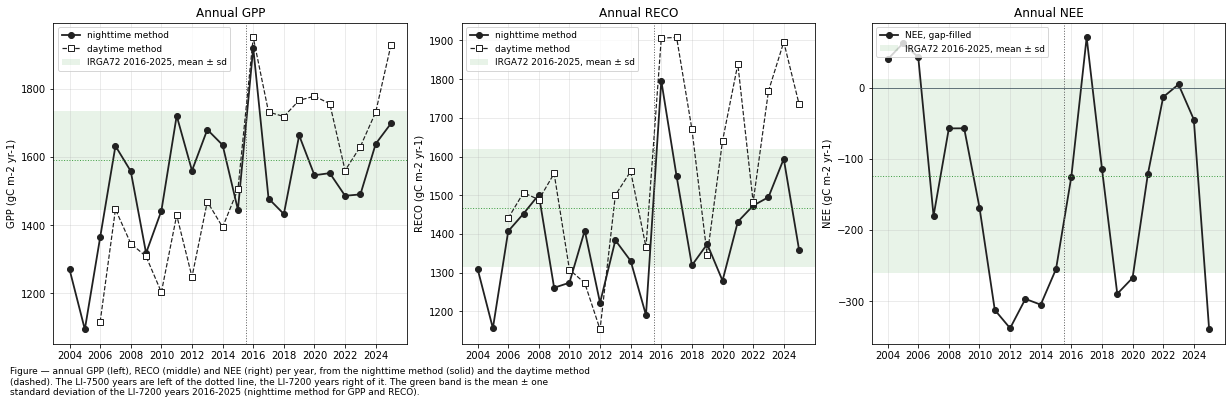

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5.5), dpi=72, layout="constrained", sharex=True)
_x = annual.index.to_numpy()
for _ax, (_nt, _dtc, _title) in zip(axs, (('GPP (NT)', 'GPP (DT)', 'GPP'), ('RECO (NT)', 'RECO (DT)', 'RECO'),
                                          ('NEE', None, 'NEE'))):
    _ax.plot(_x, annual[_nt], color=COLORS['nee'], marker='o', lw=1.8,
             label="nighttime method" if _dtc else "NEE, gap-filled")
    if _dtc:
        _ax.plot(_x, annual[_dtc], color=COLORS['nee'], marker='s', mfc='white', lw=1.2, ls='--',
                 label="daytime method")
    ref_band(_ax, annual[_nt])
    _ax.axvline(2015.5, color='#616161', lw=1, ls=':')
    _ax.set_title(f"Annual {_title}")
    _ax.set_ylabel(f"{_title} ({units_sum} yr-1)")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
axs[2].axhline(0, color='#455A64', lw=0.8)
axs[0].set_xticks(range(IRGA75_YEARS[0], IRGA72_YEARS[1] + 1, 2))
figcap(fig, f"annual GPP (left), RECO (middle) and NEE (right) per year, from the nighttime method "
            f"(solid) and the daytime method (dashed). The LI-7500 years are left of the dotted line, "
            f"the LI-7200 years right of it. The green band is the mean ± one standard deviation of the "
            f"LI-7200 years {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]} (nighttime method for GPP and RECO).")
fig.show()

`GPP` of the nighttime method is lowest in 2004-2006, reaches the level of the LI-7200 years in
2007, and is lower again in 2008-2009. Its `RECO` shows no step at the change of analyser. The
daytime method gives a lower level of both `GPP` and `RECO` throughout the LI-7500 years and a
step at the change of analyser in 2016.

## Seasonal cycles

In [12]:
MCOLS = ['nee', 'gpp_nt', 'reco_nt', 'gpp_dt', 'reco_dt', 'dt_rest', 'nee_day', 'nee_night']
monthly_y = F.groupby(['year', 'month'])[MCOLS].sum(min_count=1) * UMOL_TO_GC
_dtc = ['gpp_dt', 'reco_dt', 'dt_rest']
monthly_y.loc[~monthly_y.index.get_level_values('year').isin(DT_YEARS), _dtc] = np.nan


def group_monthly(group):
    """Mean monthly sums of a group (gC m-2), the daytime columns over its complete DT years."""
    yrs = years_of(group)
    out = monthly_y.loc[yrs].groupby('month').mean()
    dt_yrs = [y for y in yrs if y in DT_YEARS]
    out[_dtc] = monthly_y.loc[dt_yrs, _dtc].groupby('month').mean() if dt_yrs else np.nan
    # NEE over the same years as the daytime columns, so their difference closes.
    out['nee_dtyears'] = monthly_y.loc[dt_yrs, 'nee'].groupby('month').mean() if dt_yrs else np.nan
    return out


GM = {g: group_monthly(g) for g in (*GROUPS, '2005-2009')}
print("Groups and their years: " + "; ".join(
    f"{g}: {years_of(g)[0]}-{years_of(g)[-1]} (DT {', '.join(str(y) for y in years_of(g) if y in DT_YEARS)})"
    for g in GM))

Groups and their years: 2005-2007: 2005-2007 (DT 2006, 2007); 2008-2009: 2008-2009 (DT 2008, 2009); 2010-2015: 2010-2015 (DT 2010, 2011, 2012, 2013, 2014, 2015); IRGA72 2016-2025: 2016-2025 (DT 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025); 2005-2009: 2005-2009 (DT 2006, 2007, 2008, 2009)


### 📋 Table: mean monthly NEE, GPP and RECO per group, nighttime method

In [13]:
_rows = {}
for g in GROUPS:
    for _c, _lab in (('nee', 'NEE'), ('gpp_nt', 'GPP'), ('reco_nt', 'RECO')):
        _rows[f"{_lab}, {g}"] = GM[g][_c]
cycles = pd.DataFrame(_rows)
cycles.index = [calendar.month_abbr[m] for m in cycles.index]
cycles.loc['year'] = cycles.sum()
cycles.index.name = 'MONTH'
display(styled(cycles, caption=f"mean monthly sums in {units_sum} per group, nighttime method: NEE, GPP "
                               f"and RECO. The last row is the sum of the months",
               subset=[c for c in cycles.columns if c.startswith('NEE')]))

Table — mean monthly sums in gC m-2 per group, nighttime method: NEE, GPP and RECO. The last row is
the sum of the months



,"NEE, 2005-2007","GPP, 2005-2007","RECO, 2005-2007","NEE, 2008-2009","GPP, 2008-2009","RECO, 2008-2009","NEE, 2010-2015","GPP, 2010-2015","RECO, 2010-2015","NEE, IRGA72 2016-2025","GPP, IRGA72 2016-2025","RECO, IRGA72 2016-2025"
MONTH,,,,,,,,,,,,
Jan,82,31,113,85,-12,73,62,23,86,81,-6,75
Feb,55,11,66,74,2,76,52,8,60,60,15,75
Mar,44,29,73,43,39,83,36,31,66,37,59,96
Apr,27,77,104,35,77,111,10,90,101,5,117,122
May,-85,215,130,-79,237,158,-115,251,136,-112,254,142
Jun,-100,257,157,-128,276,148,-138,271,133,-145,319,174
Jul,-80,234,154,-112,252,140,-120,261,141,-131,289,158
Aug,-82,210,128,-72,252,180,-94,258,164,-82,241,159
Sep,-36,178,142,-56,186,130,-66,190,124,-59,203,144


### 📊 Plot: mean seasonal cycles of GPP, RECO and NEE per group

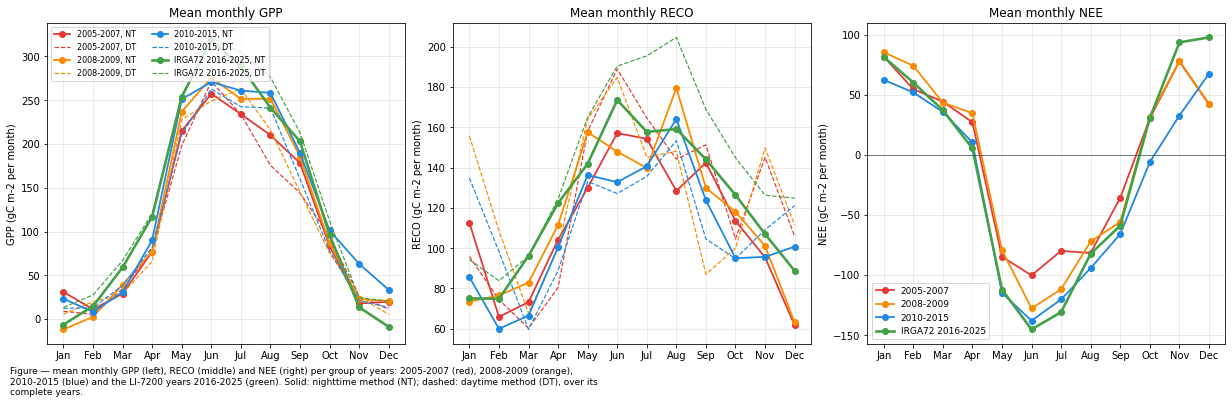

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5.5), dpi=72, layout="constrained")
_m = range(1, 13)
for g in GROUPS:
    _lw = 2.6 if g == REF else 1.8
    axs[0].plot(_m, GM[g]['gpp_nt'], color=COLORS[g], lw=_lw, marker='o', label=f"{g}, NT")
    axs[0].plot(_m, GM[g]['gpp_dt'], color=COLORS[g], lw=1.2, ls='--', label=f"{g}, DT")
    axs[1].plot(_m, GM[g]['reco_nt'], color=COLORS[g], lw=_lw, marker='o', label=f"{g}, NT")
    axs[1].plot(_m, GM[g]['reco_dt'], color=COLORS[g], lw=1.2, ls='--', label=f"{g}, DT")
    axs[2].plot(_m, GM[g]['nee'], color=COLORS[g], lw=_lw, marker='o', label=g)
for _ax, _t in zip(axs, ('GPP', 'RECO', 'NEE')):
    _ax.set_title(f"Mean monthly {_t}")
    _ax.set_ylabel(f"{_t} ({units_sum} per month)")
    _ax.grid(alpha=0.3)
    month_axis(_ax)
axs[2].axhline(0, color='#455A64', lw=0.8)
axs[0].legend(fontsize=8, ncol=2)
axs[2].legend(fontsize=9)
figcap(fig, "mean monthly GPP (left), RECO (middle) and NEE (right) per group of years: 2005-2007 "
            "(red), 2008-2009 (orange), 2010-2015 (blue) and the LI-7200 years 2016-2025 (green). "
            "Solid: nighttime method (NT); dashed: daytime method (DT), over its complete years.")
fig.show()

The early groups reach a lower peak of `GPP` in June and July than the LI-7200 years, 2005-2007
also in August and September. `RECO` of the nighttime method follows a similar seasonal course in
all groups. In `NEE`, 2005-2007 has the weakest summer uptake; 2008-2009 differs from the LI-7200
years mainly from January to June.

## Monthly parts of the difference in NEE

Per group of LI-7500 years, the difference of each month to the LI-7200 years, split three ways:
into the parts of the nighttime method (`−ΔGPP`, `ΔRECO`), into those of the daytime method
(`−ΔGPP`, `ΔRECO`, `Δrest`), and into the daytime and nighttime half-hours of `NEE` itself (flag
`DAYTIME`). The last split needs no model. The daytime method covers only its complete years, and
`ΔNEE, DT years` is the difference in `NEE` over those same years, which its three parts add up to.

In [15]:
def monthly_parts(group):
    """Monthly differences of a group to the LI-7200 years, as contributions to ΔNEE (gC m-2)."""
    a, r = GM[group], GM[REF]
    out = pd.DataFrame({
        'ΔNEE': a['nee'] - r['nee'],
        'ΔNEE, day': a['nee_day'] - r['nee_day'],
        'ΔNEE, night': a['nee_night'] - r['nee_night'],
        'NT: −ΔGPP': -(a['gpp_nt'] - r['gpp_nt']),
        'NT: ΔRECO': a['reco_nt'] - r['reco_nt'],
        'ΔNEE, DT years': a['nee_dtyears'] - r['nee'],
        'DT: −ΔGPP': -(a['gpp_dt'] - r['gpp_dt']),
        'DT: ΔRECO': a['reco_dt'] - r['reco_dt'],
        'DT: Δrest': a['dt_rest'] - r['dt_rest'],
    })
    out.index = [calendar.month_abbr[m] for m in out.index]
    out.loc['year'] = out.sum()
    out.index.name = 'MONTH'
    return out


PARTS = {g: monthly_parts(g) for g in (*EARLY_GROUPS, '2005-2009')}

### 📋 Table: monthly parts of the difference, 2005-2007

In [16]:
_g = '2005-2007'
display(styled(PARTS[_g], caption=f"{_g} minus the LI-7200 years {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, mean "
                                  f"monthly sums in {units_sum}, as contributions to ΔNEE; daytime method over "
                                  f"{', '.join(str(y) for y in years_of(_g) if y in DT_YEARS)}. Positive: less "
                                  f"uptake than the LI-7200 years"))

Table — 2005-2007 minus the LI-7200 years 2016-2025, mean monthly sums in gC m-2, as contributions
to ΔNEE; daytime method over 2006, 2007. Positive: less uptake than the LI-7200 years



,ΔNEE,"ΔNEE, day","ΔNEE, night",NT: −ΔGPP,NT: ΔRECO,"ΔNEE, DT years",DT: −ΔGPP,DT: ΔRECO,DT: Δrest
MONTH,,,,,,,,,
Jan,0,6,-6,-37,38,-6,4,2,-12
Feb,-5,5,-10,4,-9,-1,22,-9,-13
Mar,7,16,-9,30,-23,-9,32,-36,-5
Apr,22,26,-4,40,-18,23,42,-44,24
May,27,35,-8,39,-12,14,57,-7,-36
Jun,45,49,-4,61,-16,41,50,-1,-8
Jul,51,53,-2,54,-3,58,71,-31,18
Aug,1,15,-14,31,-31,-3,101,-61,-44
Sep,23,27,-4,25,-2,23,69,-18,-28


### 📋 Table: monthly parts of the difference, 2008-2009

In [17]:
_g = '2008-2009'
display(styled(PARTS[_g], caption=f"{_g} minus the LI-7200 years {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, mean "
                                  f"monthly sums in {units_sum}, as contributions to ΔNEE. Positive: less "
                                  f"uptake than the LI-7200 years"))

Table — 2008-2009 minus the LI-7200 years 2016-2025, mean monthly sums in gC m-2, as contributions
to ΔNEE. Positive: less uptake than the LI-7200 years



,ΔNEE,"ΔNEE, day","ΔNEE, night",NT: −ΔGPP,NT: ΔRECO,"ΔNEE, DT years",DT: −ΔGPP,DT: ΔRECO,DT: Δrest
MONTH,,,,,,,,,
Jan,4,17,-13,6,-2,4,8,61,-65
Feb,14,14,0,12,2,14,8,25,-19
Mar,6,18,-12,20,-13,6,38,-28,-3
Apr,29,33,-4,40,-11,29,55,-24,-1
May,33,26,7,17,16,33,27,-1,7
Jun,17,26,-8,43,-26,17,73,-6,-49
Jul,19,22,-3,37,-18,19,42,-50,28
Aug,10,9,2,-10,20,10,60,-57,6
Sep,3,15,-12,17,-14,3,68,-82,17


### 📋 Table: monthly parts of the difference, 2010-2015

In [18]:
_g = '2010-2015'
display(styled(PARTS[_g], caption=f"{_g} minus the LI-7200 years {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, mean "
                                  f"monthly sums in {units_sum}, as contributions to ΔNEE. Positive: less "
                                  f"uptake than the LI-7200 years"))

Table — 2010-2015 minus the LI-7200 years 2016-2025, mean monthly sums in gC m-2, as contributions
to ΔNEE. Positive: less uptake than the LI-7200 years



,ΔNEE,"ΔNEE, day","ΔNEE, night",NT: −ΔGPP,NT: ΔRECO,"ΔNEE, DT years",DT: −ΔGPP,DT: ΔRECO,DT: Δrest
MONTH,,,,,,,,,
Jan,-19,-6,-13,-30,11,-19,1,41,-61
Feb,-8,6,-14,7,-15,-8,14,15,-37
Mar,-1,7,-8,28,-30,-1,29,-36,6
Apr,5,10,-5,27,-22,5,39,-36,2
May,-3,3,-6,3,-6,-3,44,-32,-15
Jun,7,17,-9,48,-41,7,59,-63,12
Jul,11,15,-5,28,-17,11,62,-60,8
Aug,-12,-7,-5,-17,5,-12,35,-51,4
Sep,-7,4,-11,13,-20,-7,53,-64,5


### 📊 Plot: monthly parts of the difference per group

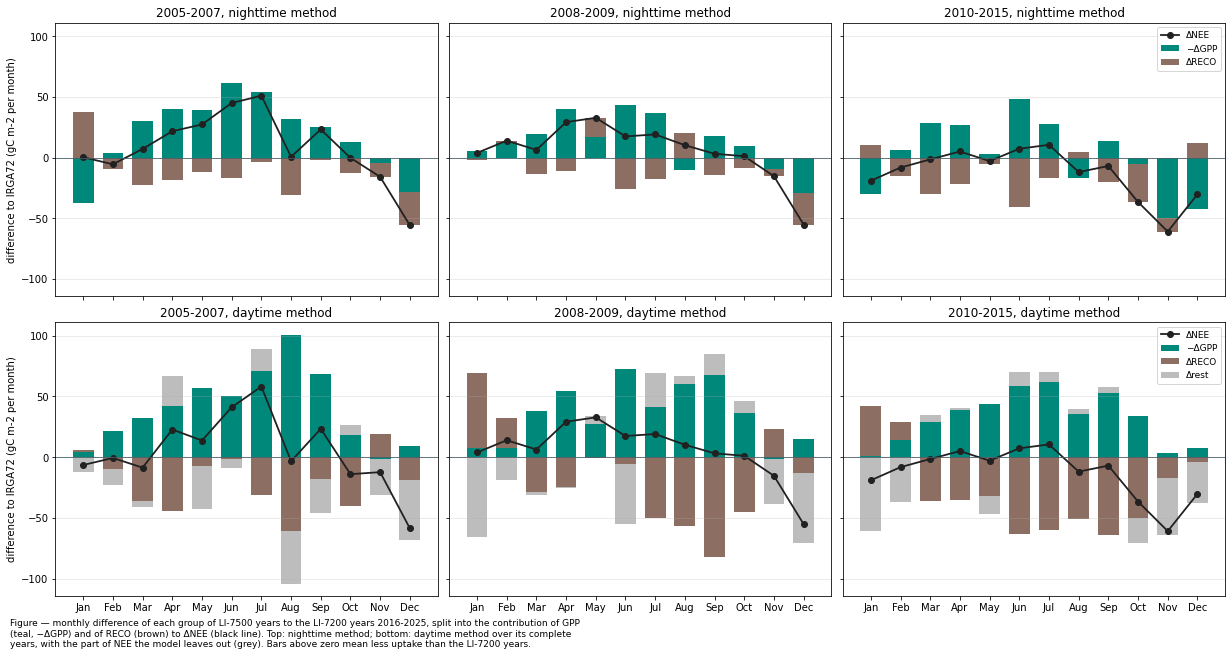

In [19]:
fig, axs = plt.subplots(2, 3, figsize=(17, 9), dpi=72, layout="constrained", sharey=True, sharex=True)
_m = np.arange(1, 13)
for _j, g in enumerate(EARLY_GROUPS):
    _p = PARTS[g].drop('year')
    for _i, (_gpp, _reco, _net, _rest, _lab) in enumerate((
            ('NT: −ΔGPP', 'NT: ΔRECO', 'ΔNEE', None, 'nighttime method'),
            ('DT: −ΔGPP', 'DT: ΔRECO', 'ΔNEE, DT years', 'DT: Δrest', 'daytime method'))):
        _ax = axs[_i, _j]
        _parts = [(_gpp, COLORS['gpp'], '−ΔGPP'), (_reco, COLORS['reco'], 'ΔRECO')]
        if _rest:
            _parts.append((_rest, COLORS['rest'], 'Δrest'))
        _pos = np.zeros(12)
        _neg = np.zeros(12)
        for _c, _col, _l in _parts:
            _v = _p[_c].to_numpy(dtype=float)
            _base = np.where(_v >= 0, _pos, _neg)
            _ax.bar(_m, _v, bottom=_base, color=_col, width=0.7, label=_l)
            _pos += np.where(_v >= 0, _v, 0)
            _neg += np.where(_v < 0, _v, 0)
        _ax.plot(_m, _p[_net].to_numpy(dtype=float), color=COLORS['nee'], marker='o', lw=1.8, label='ΔNEE')
        _ax.axhline(0, color='#455A64', lw=0.8)
        _ax.set_title(f"{g}, {_lab}")
        _ax.grid(alpha=0.3, axis='y')
        month_axis(_ax)
        if _j == 0:
            _ax.set_ylabel(f"difference to IRGA72 ({units_sum} per month)")
        if _j == 2:
            _ax.legend(fontsize=9)
figcap(fig, f"monthly difference of each group of LI-7500 years to the LI-7200 years {IRGA72_YEARS[0]}-"
            f"{IRGA72_YEARS[1]}, split into the contribution of GPP (teal, −ΔGPP) and of RECO (brown) to "
            f"ΔNEE (black line). Top: nighttime method; bottom: daytime method over its complete years, "
            f"with the part of NEE the model leaves out (grey). Bars above zero mean less uptake than "
            f"the LI-7200 years.")
fig.show()

In 2005-2007 the difference builds up from March to September, most in June and July, and is
almost entirely daytime `NEE`; the nighttime method puts it into `GPP`. In 2008-2009 every month
from January to July adds a similar amount, again in the daytime half-hours. In 2010-2015 the
months partly cancel. The daytime method assigns a larger `GPP` deficit in every group and offsets
it with lower `RECO`, also in 2010-2015.

</br>

# 2 Responses under matched conditions

The annual and monthly sums mix the response of the forest with the weather of each year. Here
the two are separated: `GPP` and `RECO` are compared at the same light and temperature, and the
parameters of both partitioning methods are compared per year. The comparisons use the peak
season, June to August, so that the timing of leaf-out and leaf fall does not enter.

The light response uses the measured daytime records (`NEE_L3.1_L3.3_CUT_50_QCF`, `DAYTIME`, and
measured PPFD above 20 µmol m⁻² s⁻¹). On these records `GPP` of the nighttime method is
`RECO − NEE`, the measured flux minus the modelled respiration; `GPP` of the daytime method is a
model value.

In [20]:
# The fixed distributions: all peak-season daytime half-hours of 2005-2025 with measured PPFD,
# whether or not a flux was measured. A standardised mean is what a year would show under the
# light and temperature of an average peak season.
_w = F[(F['year'] >= FIRST_LIGHT_YEAR) & F['month'].isin(PEAK) & F['day'] & F['ppfd_meas']
       & (F['ppfd'] > DAY_PPFD)]
W_DAY = _w.groupby(cells(_w, 'ppfd', PPFD_BINS, 'ta', TA_BINS), observed=True).size()
W_DAY = W_DAY / W_DAY.sum()
_whl = _w[_w['ppfd'] > HIGH_PPFD]
W_HL = _whl.groupby(pd.cut(_whl['ta'], TA_BINS), observed=True).size()
W_HL = W_HL / W_HL.sum()
_wn = F[(F['year'] >= FIRST_LIGHT_YEAR) & F['month'].isin(PEAK) & ~F['day']]
W_NIGHT = _wn.groupby(pd.cut(_wn['ta'], NIGHT_TA_BINS), observed=True).size()
W_NIGHT = W_NIGHT / W_NIGHT.sum()

LD = F[(F['year'] >= FIRST_LIGHT_YEAR) & F['month'].isin(PEAK) & F['meas'] & F['day'] & F['ppfd_meas']
       & (F['ppfd'] > DAY_PPFD)].copy()
LN = F[(F['year'] >= FIRST_LIGHT_YEAR) & F['month'].isin(PEAK) & F['meas'] & ~F['day']].copy()
print(f"day cells: {len(W_DAY)}, high-light TA cells: {len(W_HL)}, night cells: {len(W_NIGHT)}")
print(pd.DataFrame({'peak-season daytime records': LD.groupby('group').size(),
                    'peak-season nighttime records': LN.groupby('group').size()}).T)

day cells: 40, high-light TA cells: 5, night cells: 9
group                          2005-2007  2008-2009  2010-2015  \
peak-season daytime records         4192       2769       7881   
peak-season nighttime records       1513        960       2673   

group                          IRGA72 2016-2025  
peak-season daytime records               16913  
peak-season nighttime records              6306  


## Light response of GPP

### 📊 Plot: light response of GPP in classes of air temperature, June to August

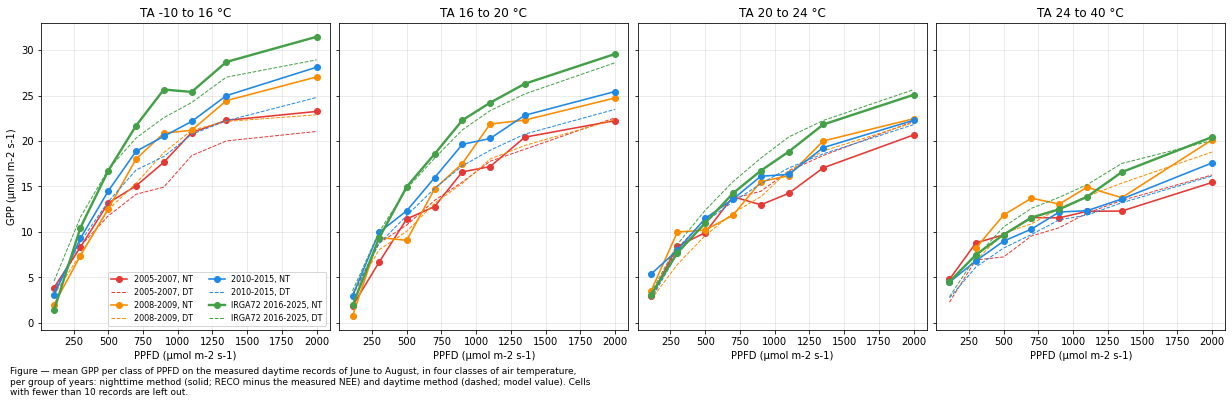

In [21]:
_npan = len(TA_PANELS) - 1
fig, axs = plt.subplots(1, _npan, figsize=(17, 5.5), dpi=72, layout="constrained", sharey=True)
_centres = [(a + b) / 2 for a, b in zip(PPFD_BINS[:-1], PPFD_BINS[1:])]
LD['pbin'] = pd.cut(LD['ppfd'], PPFD_BINS)
LD['tpanel'] = pd.cut(LD['ta'], TA_PANELS)
for _ax, _cls in zip(axs, LD['tpanel'].cat.categories):
    _s = LD[LD['tpanel'] == _cls]
    for g in GROUPS:
        _gg = _s[_s['group'] == g].groupby('pbin', observed=False)
        _ax.plot(_centres, _gg['gpp_nt'].mean().where(_gg.size() >= MIN_CELL_N).to_numpy(),
                 color=COLORS[g], marker='o', lw=2.4 if g == REF else 1.6, label=f"{g}, NT")
        _ax.plot(_centres, _gg['gpp_dt'].mean().where(_gg.size() >= MIN_CELL_N).to_numpy(),
                 color=COLORS[g], lw=1.0, ls='--', label=f"{g}, DT")
    _ax.set_title(f"TA {_cls.left:g} to {_cls.right:g} °C")
    _ax.set_xlabel(f"PPFD ({units})")
    _ax.grid(alpha=0.3)
axs[0].set_ylabel(f"GPP ({units})")
axs[0].legend(fontsize=8, ncol=2)
figcap(fig, f"mean GPP per class of PPFD on the measured daytime records of June to August, in four "
            f"classes of air temperature, per group of years: nighttime method (solid; RECO minus the "
            f"measured NEE) and daytime method (dashed; model value). Cells with fewer than "
            f"{MIN_CELL_N} records are left out.")
fig.show()

At the same light and air temperature, `GPP` of 2005-2007 is the lowest of all groups, and the
difference grows with light. It is largest at air temperatures below 20 °C, where the LI-7200
years reach their highest `GPP`; above 24 °C the groups are close. At high light 2008-2009 and
2010-2015 lie between 2005-2007 and the LI-7200 years.

### 📋 Table: standardised peak-season daytime fluxes per year

In [22]:
LD['tbin'] = pd.cut(LD['ta'], TA_BINS)
_rows = {}
for _y, _g in LD.groupby('year'):
    _keys = [_g['pbin'], _g['tbin']]
    _r = {lab: std_mean(_g, W_DAY, _keys, c)['mean'] for c, lab in (
        ('nee_meas', 'NEE'), ('gpp_nt', 'GPP (NT)'), ('reco_nt', 'RECO (NT)'), ('gpp_dt', 'GPP (DT)'),
        ('reco_dt', 'RECO (DT)'))}
    _hl = _g[_g['ppfd'] > HIGH_PPFD]
    _r[f'GPP (NT), PPFD > {HIGH_PPFD}'] = std_mean(_hl, W_HL, [pd.cut(_hl['ta'], TA_BINS)], 'gpp_nt')['mean']
    _r[f'GPP (DT), PPFD > {HIGH_PPFD}'] = std_mean(_hl, W_HL, [pd.cut(_hl['ta'], TA_BINS)], 'gpp_dt')['mean']
    _r['cover'] = std_mean(_g, W_DAY, _keys, 'nee_meas')['cover']
    _r['records'] = len(_g)
    _rows[_y] = _r
STD_DAY = pd.DataFrame(_rows).T
STD_DAY.index.name = 'YEAR'
_fmt = {c: "{:.2f}" for c in STD_DAY.columns}
_fmt['records'] = "{:,.0f}"
display(styled(STD_DAY, caption=f"per year, the mean of each flux ({units}) over the measured daytime records "
                                f"of June to August, standardised to the common distribution of PPFD and air "
                                f"temperature of {FIRST_LIGHT_YEAR}-{IRGA72_YEARS[1]}: what the year would show "
                                f"under the light and temperature of an average peak season. The two "
                                f"'PPFD > {HIGH_PPFD}' columns are the light-saturated GPP, standardised over "
                                f"air temperature only. 'cover': the share of the common distribution the "
                                f"year's records cover. The daytime method starts in {DT_YEARS[0]}",
               fmt=_fmt, cmap=None))

Table — per year, the mean of each flux (µmol m-2 s-1) over the measured daytime records of June to
August, standardised to the common distribution of PPFD and air temperature of 2005-2025: what the
year would show under the light and temperature of an average peak season. The two 'PPFD > 1000'
columns are the light-saturated GPP, standardised over air temperature only. 'cover': the share of
the common distribution the year's records cover. The daytime method starts in 2006



,NEE,GPP (NT),RECO (NT),GPP (DT),RECO (DT),"GPP (NT), PPFD > 1000","GPP (DT), PPFD > 1000",cover,records
YEAR,,,,,,,,,
2005,-7.50,12.06,4.56,-,-,17.00,-,0.94,"1,442"
2006,-6.71,12.07,5.36,10.90,5.04,18.80,16.90,0.99,"1,430"
2007,-8.91,13.86,4.96,14.74,6.68,19.92,21.51,0.92,"1,320"
2008,-8.53,13.42,4.89,12.78,5.86,20.36,19.27,0.97,"1,434"
2009,-8.39,13.62,5.23,12.95,5.00,21.86,20.19,0.97,"1,335"
2010,-10.06,15.37,5.32,14.06,4.58,21.93,19.59,0.96,"1,116"
2011,-9.78,13.81,4.03,13.67,4.36,19.46,20.14,0.93,"1,243"
2012,-10.33,15.31,4.98,12.65,4.67,22.41,18.77,0.97,"1,154"
2013,-9.58,15.25,5.68,13.95,4.58,23.07,21.40,0.98,"1,368"


### 📋 Table: standardised peak-season daytime fluxes per group, difference to the LI-7200 years

In [23]:
_t = STD_DAY.drop(columns=['cover', 'records'])
std_groups = diff_to_ref(_t, EARLY_GROUPS, sign={c: -1 for c in _t.columns if c.startswith('GPP')})
std_groups.columns = ['ΔNEE' if c == 'NEE' else (f"−Δ{c}" if c.startswith('GPP') else f"Δ{c}")
                      for c in std_groups.columns]
display(styled(std_groups, caption=f"per group, the mean of the standardised peak-season daytime values of the "
                                   f"table above minus that of the LI-7200 years, in {units}. GPP enters with "
                                   f"a negative sign, so every column is a contribution to ΔNEE and positive "
                                   f"means less uptake. NT: ΔNEE = ΔRECO (NT) − ΔGPP (NT) holds per record, "
                                   f"so the two NT columns add up to ΔNEE. The last row is the standard "
                                   f"deviation of the LI-7200 years", fmt="{:.2f}"))

Table — per group, the mean of the standardised peak-season daytime values of the table above minus
that of the LI-7200 years, in µmol m-2 s-1. GPP enters with a negative sign, so every column is a
contribution to ΔNEE and positive means less uptake. NT: ΔNEE = ΔRECO (NT) − ΔGPP (NT) holds per
record, so the two NT columns add up to ΔNEE. The last row is the standard deviation of the LI-7200
years



,ΔNEE,−ΔGPP (NT),ΔRECO (NT),−ΔGPP (DT),ΔRECO (DT),"−ΔGPP (NT), PPFD > 1000","−ΔGPP (DT), PPFD > 1000"
2005-2007,2.48,2.74,-0.26,3.07,-0.43,5.26,4.42
2008-2009,1.73,1.88,-0.15,3.02,-0.86,2.73,3.89
2010-2015,0.57,1.12,-0.55,2.58,-1.81,2.83,3.98
IRGA72 sd of years,1.34,1.76,0.62,1.91,1.13,2.54,2.41


Standardised to the same light and temperature, the peak-season daytime `NEE` of 2005-2007 has the
largest deficit, followed by 2008-2009; 2010-2015 lies within the spread of the LI-7200 years. In
the nighttime method the deficit is `GPP`, and the modelled daytime `RECO` of the early years
equals that of the LI-7200 years. The light-saturated `GPP` of 2005 and 2006 is below that of
every LI-7200 year.

## Parameters of the daytime method

### 📋 Table: light-response parameters per year, June to August

In [24]:
# One row per fitting window; a window that fell back to a respiration-only fit has ALPHA or
# BETA of zero and is left out of the medians.
_win = F[F['beta'].notna() & F['month'].isin(PEAK)]
_valid = _win[(_win['alpha'] > 0) & (_win['beta'] > 0)]
params_dt = pd.DataFrame({
    'windows': _win.groupby('year').size(),
    'valid (%)': _valid.groupby('year').size() / _win.groupby('year').size() * 100,
    f'ALPHA (µmol J-1)': _valid.groupby('year')['alpha'].median(),
    f'BETA ({units})': _valid.groupby('year')['beta'].median(),
    'K (kPa-1)': _valid.groupby('year')['k'].median(),
    f'RREF (DT, {units})': _valid.groupby('year')['rref_dt'].median(),
    'E0 (DT, K)': F[F['e0_dt'].notna() & F['month'].isin(PEAK)].groupby('year')['e0_dt'].median(),
}).reindex(range(DT_YEARS[0], IRGA72_YEARS[1] + 1))
params_dt.index.name = 'YEAR'
_fmt = {c: "{:.1f}" for c in params_dt.columns}
_fmt.update({'windows': "{:.0f}", 'ALPHA (µmol J-1)': "{:.3f}", 'K (kPa-1)': "{:.3f}"})
display(styled(params_dt, caption="per year, the medians of the parameters of the daytime method over its "
                                  "fitting windows of June to August with ALPHA and BETA above zero: initial "
                                  "slope ALPHA, GPP at light saturation BETA (at VPD below the threshold of the "
                                  "model), VPD sensitivity K and basal respiration RREF at 15 °C; E0 over the "
                                  "windows in which it is reported. 'valid (%)': the share of windows used",
               fmt=_fmt, cmap=None))

Table — per year, the medians of the parameters of the daytime method over its fitting windows of
June to August with ALPHA and BETA above zero: initial slope ALPHA, GPP at light saturation BETA (at
VPD below the threshold of the model), VPD sensitivity K and basal respiration RREF at 15 °C; E0
over the windows in which it is reported. 'valid (%)': the share of windows used



,windows,valid (%),ALPHA (µmol J-1),BETA (µmol m-2 s-1),K (kPa-1),"RREF (DT, µmol m-2 s-1)","E0 (DT, K)"
YEAR,,,,,,,
2006,35,88.6,0.059,41.7,0.027,3.8,135.4
2007,42,95.2,0.077,50.3,0.035,4.7,205.0
2008,39,97.4,0.064,50.3,0.093,5.2,271.9
2009,33,93.9,0.058,55.3,0.089,4.1,140.4
2010,33,90.9,0.077,51.4,0.060,3.6,100.6
2011,33,97.0,0.070,53.4,0.059,3.2,179.1
2012,28,92.9,0.087,48.9,0.064,4.6,205.0
2013,33,100.0,0.064,55.5,0.099,4.0,236.5
2014,34,94.1,0.067,50.1,0.000,3.8,187.8


### 📊 Plot: light-response parameters per year

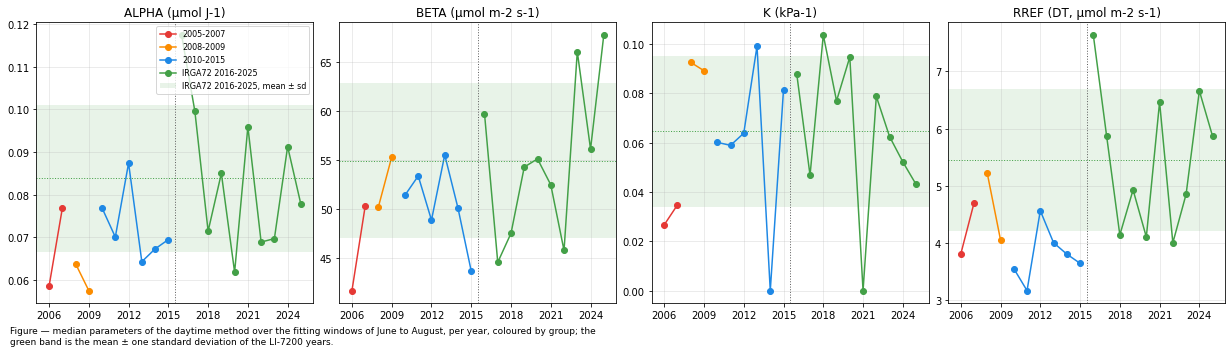

In [25]:
fig, axs = plt.subplots(1, 4, figsize=(17, 4.8), dpi=72, layout="constrained", sharex=True)
for _ax, _c in zip(axs, ['ALPHA (µmol J-1)', f'BETA ({units})', 'K (kPa-1)', f'RREF (DT, {units})']):
    _v = params_dt[_c]
    for g in GROUPS:
        _s = _v.reindex(years_of(g)).dropna()
        _ax.plot(_s.index, _s, color=COLORS[g], marker='o', lw=1.5, label=g)
    ref_band(_ax, _v, label=_c.startswith('ALPHA'))
    _ax.axvline(2015.5, color='#616161', lw=1, ls=':')
    _ax.set_title(_c)
    _ax.grid(alpha=0.3)
axs[0].legend(fontsize=8)
axs[0].set_xticks(range(DT_YEARS[0], IRGA72_YEARS[1] + 1, 3))
figcap(fig, "median parameters of the daytime method over the fitting windows of June to August, per "
            "year, coloured by group; the green band is the mean ± one standard deviation of the LI-7200 "
            "years.")
fig.show()

The initial slope `ALPHA` and the basal respiration `RREF` of the daytime method are lower in most
LI-7500 years than in the LI-7200 years. `BETA`, the light-saturated `GPP`, is lowest in 2006 and
otherwise within the range of the LI-7200 years, though mostly below their mean. The parameters
change at the change of analyser rather than within the LI-7500 record; this is the offset between
the periods seen in the annual sums of the daytime method.

## Respiration of the nighttime method

### 📋 Table: temperature response of RECO per year

In [26]:
LN['tbin'] = pd.cut(LN['ta'], NIGHT_TA_BINS)
_pk = F[F['month'].isin(PEAK)]
_rref = _pk.groupby('year')['rref_nt'].mean()
_e0 = F.groupby('year')['e0_nt'].first()
resp_nt = pd.DataFrame({
    'E0 (NT, K)': _e0,
    f'RREF (NT) Jun-Aug ({units})': _rref,
    f'RREF (NT) year ({units})': F.groupby('year')['rref_nt'].mean(),
    'RECO (NT) at 10 °C': lloyd_taylor(10, _rref, _e0),
    'RECO (NT) at 20 °C': lloyd_taylor(20, _rref, _e0),
    'night NEE measured, std': pd.Series({y: std_mean(g, W_NIGHT, [g['tbin']], 'nee_meas')['mean']
                                          for y, g in LN.groupby('year')}),
    'night RECO (NT), same records, std': pd.Series({y: std_mean(g, W_NIGHT, [g['tbin']], 'reco_nt')['mean']
                                                     for y, g in LN.groupby('year')}),
    'night records': LN.groupby('year').size(),
})
resp_nt.index.name = 'YEAR'
_fmt = {c: "{:.2f}" for c in resp_nt.columns}
_fmt.update({'E0 (NT, K)': "{:.0f}", 'night records': "{:,.0f}"})
display(styled(resp_nt, caption=f"per year, the temperature response of the nighttime method: its E0 (one per "
                                f"year), the mean reference respiration RREF at {LT_TREF:g} °C over June to "
                                f"August and over the year, and RECO at 10 and 20 °C from the June-August RREF "
                                f"and E0, in {units}. The last columns are the measured nighttime NEE of June "
                                f"to August and RECO (NT) on the same records, both standardised to the common "
                                f"distribution of night air temperature of {FIRST_LIGHT_YEAR}-"
                                f"{IRGA72_YEARS[1]}", fmt=_fmt, cmap=None))

Table — per year, the temperature response of the nighttime method: its E0 (one per year), the mean
reference respiration RREF at 15 °C over June to August and over the year, and RECO at 10 and 20 °C
from the June-August RREF and E0, in µmol m-2 s-1. The last columns are the measured nighttime NEE
of June to August and RECO (NT) on the same records, both standardised to the common distribution of
night air temperature of 2005-2025



,"E0 (NT, K)",RREF (NT) Jun-Aug (µmol m-2 s-1),RREF (NT) year (µmol m-2 s-1),RECO (NT) at 10 °C,RECO (NT) at 20 °C,"night NEE measured, std","night RECO (NT), same records, std",night records
YEAR,,,,,,,,
2004,57,4.28,3.83,3.93,4.59,-,-,-
2005,116,3.95,3.72,3.34,4.57,4.67,4.51,506
2006,117,4.57,4.71,3.85,5.28,5.74,5.27,543
2007,113,4.40,4.63,3.73,5.07,4.98,4.92,464
2008,107,4.28,4.81,3.66,4.89,4.75,4.94,488
2009,135,4.72,3.93,3.87,5.58,5.18,5.35,472
2010,185,4.62,4.96,3.52,5.81,5.22,4.82,391
2011,104,3.60,4.35,3.09,4.09,3.86,3.80,354
2012,103,4.27,3.80,3.68,4.85,5.31,5.25,404


### 📊 Plot: respiration at 10 and 20 °C per year

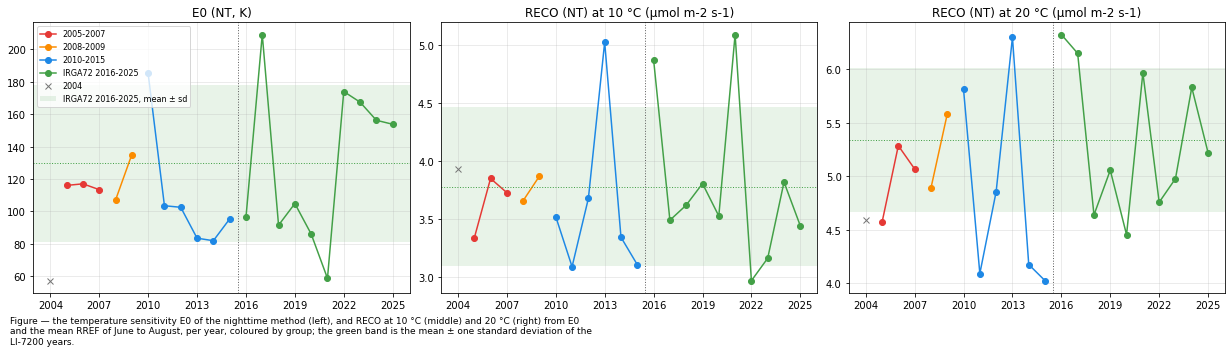

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8), dpi=72, layout="constrained", sharex=True)
for _ax, _c in zip(axs, ['E0 (NT, K)', 'RECO (NT) at 10 °C', 'RECO (NT) at 20 °C']):
    _v = resp_nt[_c]
    for g in GROUPS:
        _s = _v.reindex(years_of(g)).dropna()
        _ax.plot(_s.index, _s, color=COLORS[g], marker='o', lw=1.5, label=g)
    _s = _v.loc[[IRGA75_YEARS[0]]]
    _ax.plot(_s.index, _s, color='#757575', marker='x', ls='none', label=str(IRGA75_YEARS[0]))
    ref_band(_ax, _v, label=_c.startswith('E0'))
    _ax.axvline(2015.5, color='#616161', lw=1, ls=':')
    _ax.set_title(_c if _c.startswith('E0') else f"{_c} ({units})")
    _ax.grid(alpha=0.3)
axs[0].legend(fontsize=8)
axs[0].set_xticks(range(IRGA75_YEARS[0], IRGA72_YEARS[1] + 1, 3))
figcap(fig, "the temperature sensitivity E0 of the nighttime method (left), and RECO at 10 °C (middle) "
            "and 20 °C (right) from E0 and the mean RREF of June to August, per year, coloured by group; "
            "the green band is the mean ± one standard deviation of the LI-7200 years.")
fig.show()

`E0` of the nighttime method varies strongly from year to year in both periods. `RECO` at 10 and
20 °C of the early years lies within the range of the LI-7200 years, and the measured summer
nights agree with `RECO` on the same records in every year. Respiration does not set the early
years apart.

## Peak capacity and season length of GPP

Annual `GPP` is the product of a peak capacity and an effective season length. The capacity is
the highest 15-day running mean of daily `GPP`; the effective season length is annual `GPP`
divided by the capacity, the number of days at peak rate that would give the annual sum. The
difference of a group to the LI-7200 years then splits exactly into a capacity part,
`(CAP − CAP_ref) · L_ref`, and a length part, `CAP · (L − L_ref)`, for the group means of `CAP`
and `L`; the remainder is the difference between the mean of a product and the product of the
means.

In [28]:
daily = F[['nee', 'gpp_nt', 'gpp_dt']].resample('D').sum(min_count=48) * UMOL_TO_GC
smooth = daily.rolling(SMOOTH_DAYS, center=True, min_periods=SMOOTH_DAYS // 2 + 1).mean()
smooth['year'] = smooth.index.year
smooth['doy'] = smooth.index.dayofyear


def gpp_season(s, cap):
    """First and last DOY on which the smoothed daily GPP is at or above GPP_FRACTION of its peak."""
    above = s >= GPP_FRACTION * cap
    if not above.any():
        return np.nan, np.nan
    return above.idxmax().dayofyear, above[::-1].idxmax().dayofyear


def nee_season(s):
    """Spring and autumn compensation points of the smoothed daily NEE.

    Spring: the first day from SPRING_FROM_DOY that starts PERSIST_DAYS of negative NEE. Autumn:
    the last day that ends PERSIST_DAYS of negative NEE.
    """
    run = s.rolling(PERSIST_DAYS).max() < 0  # True where the PERSIST_DAYS ending here are negative
    starts = run[run].index - pd.Timedelta(days=PERSIST_DAYS - 1)
    starts = starts[starts.dayofyear >= SPRING_FROM_DOY]
    if len(starts) == 0:
        return np.nan, np.nan, 0
    return starts[0].dayofyear, run[run].index[-1].dayofyear, int((s < 0).sum())


_rows = {}
for _y, _s in smooth.groupby('year'):
    _r = {}
    for _c, _lab in (('gpp_nt', 'NT'), ('gpp_dt', 'DT')):
        _tot = annual.loc[_y, f'GPP ({_lab})']
        _cap = _s[_c].max() if pd.notna(_tot) else np.nan
        _r[f'capacity {_lab} (gC m-2 d-1)'] = _cap
        _r[f'effective length {_lab} (d)'] = _tot / _cap if pd.notna(_tot) else np.nan
        _st, _en = gpp_season(_s[_c], _cap) if pd.notna(_tot) else (np.nan, np.nan)
        _r[f'GPP {_lab} high from (DOY)'] = _st
        _r[f'GPP {_lab} high to (DOY)'] = _en
    _r['NEE negative from (DOY)'], _r['NEE negative to (DOY)'], _r['days NEE < 0'] = nee_season(_s['nee'])
    _rows[_y] = _r
SEASON = pd.DataFrame(_rows).T
SEASON['carbon uptake period (d)'] = SEASON['NEE negative to (DOY)'] - SEASON['NEE negative from (DOY)'] + 1
SEASON['GPP NT high (d)'] = SEASON['GPP NT high to (DOY)'] - SEASON['GPP NT high from (DOY)'] + 1
SEASON.index.name = 'YEAR'
print(f"{len(SEASON)} years; smoothing {SMOOTH_DAYS} days, NEE persistence {PERSIST_DAYS} days, "
      f"GPP season at {GPP_FRACTION:.0%} of the peak")

22 years; smoothing 15 days, NEE persistence 10 days, GPP season at 50% of the peak


### 📋 Table: peak capacity and effective season length of GPP per year

In [29]:
_c = ['capacity NT (gC m-2 d-1)', 'effective length NT (d)', 'capacity DT (gC m-2 d-1)', 'effective length DT (d)']
cap_year = SEASON[_c].join(annual[['GPP (NT)', 'GPP (DT)']])
_fmt = {c: ("{:.2f}" if 'capacity' in c else "{:.0f}") for c in cap_year.columns}
display(styled(cap_year, caption=f"per year, the peak capacity of GPP (the highest {SMOOTH_DAYS}-day running mean "
                                 f"of daily GPP), the effective season length (annual GPP divided by the "
                                 f"capacity), and annual GPP, for the nighttime (NT) and daytime (DT) methods",
               fmt=_fmt, cmap=None))

Table — per year, the peak capacity of GPP (the highest 15-day running mean of daily GPP), the
effective season length (annual GPP divided by the capacity), and annual GPP, for the nighttime (NT)
and daytime (DT) methods



,capacity NT (gC m-2 d-1),effective length NT (d),capacity DT (gC m-2 d-1),effective length DT (d),GPP (NT),GPP (DT)
YEAR,,,,,,
2004,8.12,157,-,-,1270,-
2005,8.68,126,-,-,1094,-
2006,9.46,144,9.79,114,1364,1116
2007,9.64,169,10.83,134,1633,1447
2008,10.40,150,10.03,134,1559,1346
2009,10.25,129,10.78,121,1318,1308
2010,11.98,120,10.76,112,1443,1203
2011,10.02,172,10.41,137,1721,1429
2012,12.17,128,10.50,119,1560,1248


### 📋 Table: capacity and season-length parts of the difference in annual GPP

In [30]:
_rows = {}
for g in (*EARLY_GROUPS, '2005-2009'):
    for _lab in ('NT', 'DT'):
        _yrs = years_of(g) if _lab == 'NT' else [y for y in years_of(g) if y in DT_YEARS]
        _ref_yrs = years_of(REF)
        _cap, _len = f'capacity {_lab} (gC m-2 d-1)', f'effective length {_lab} (d)'
        C, L, G = SEASON.loc[_yrs, _cap].mean(), SEASON.loc[_yrs, _len].mean(), annual.loc[_yrs, f'GPP ({_lab})'].mean()
        Cr, Lr = SEASON.loc[_ref_yrs, _cap].mean(), SEASON.loc[_ref_yrs, _len].mean()
        Gr = annual.loc[_ref_yrs, f'GPP ({_lab})'].mean()
        _rows[(g, _lab)] = {
            'years': f"{_yrs[0]}-{_yrs[-1]}",
            'capacity (gC m-2 d-1)': C, 'capacity, IRGA72': Cr,
            'effective length (d)': L, 'effective length, IRGA72': Lr,
            'ΔGPP': G - Gr,
            'capacity part': (C - Cr) * Lr,
            'length part': C * (L - Lr),
            'remainder': (G - Gr) - (C - Cr) * Lr - C * (L - Lr),
        }
cap_split = pd.DataFrame(_rows).T
cap_split.index.names = ['group', 'method']
_num = [c for c in cap_split.columns if c != 'years']
cap_split[_num] = cap_split[_num].astype(float)
_fmt = {c: ("{:.2f}" if 'capacity (' in c or c == 'capacity, IRGA72' else "{:.0f}") for c in cap_split.columns}
display(styled(cap_split, caption=f"per group and method, the mean peak capacity and effective season length of "
                                  f"GPP and those of the LI-7200 years, and the difference in annual GPP "
                                  f"({units_sum}) split into a capacity part and a length part. Negative: less "
                                  f"GPP than the LI-7200 years. The daytime method uses its complete years",
               fmt=_fmt, subset=['ΔGPP', 'capacity part', 'length part', 'remainder']))

Table — per group and method, the mean peak capacity and effective season length of GPP and those of
the LI-7200 years, and the difference in annual GPP (gC m-2) split into a capacity part and a length
part. Negative: less GPP than the LI-7200 years. The daytime method uses its complete years



### 📊 Plot: mean daily GPP per group, absolute and relative to the peak

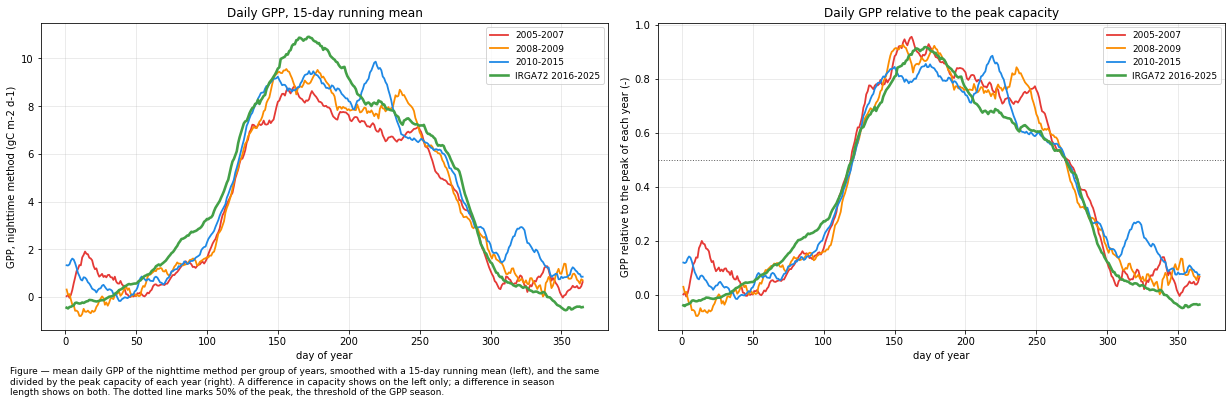

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(17, 5.5), dpi=72, layout="constrained", sharex=True)
for g in GROUPS:
    _s = smooth[smooth['year'].isin(years_of(g))]
    _abs = _s.groupby('doy')['gpp_nt'].mean().loc[:365]
    _rel = (_s['gpp_nt'] / _s['year'].map(SEASON['capacity NT (gC m-2 d-1)'])).groupby(_s['doy']).mean().loc[:365]
    _lw = 2.6 if g == REF else 1.8
    axs[0].plot(_abs.index, _abs, color=COLORS[g], lw=_lw, label=g)
    axs[1].plot(_rel.index, _rel, color=COLORS[g], lw=_lw, label=g)
axs[1].axhline(GPP_FRACTION, color='#616161', lw=1, ls=':')
axs[0].set_ylabel("GPP, nighttime method (gC m-2 d-1)")
axs[1].set_ylabel("GPP relative to the peak of each year (-)")
axs[0].set_title(f"Daily GPP, {SMOOTH_DAYS}-day running mean")
axs[1].set_title("Daily GPP relative to the peak capacity")
for _ax in axs:
    _ax.set_xlabel("day of year")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, f"mean daily GPP of the nighttime method per group of years, smoothed with a {SMOOTH_DAYS}-day "
            f"running mean (left), and the same divided by the peak capacity of each year (right). A "
            f"difference in capacity shows on the left only; a difference in season length shows on both. "
            f"The dotted line marks {GPP_FRACTION:.0%} of the peak, the threshold of the GPP season.")
fig.show()

The lower annual `GPP` of the early years comes from a lower peak capacity. The effective season
length of the nighttime method is longer than in the LI-7200 years, because a lower and broader
peak gives its annual sum over more days; this offsets part of the capacity deficit. Relative to
its peak, the seasonal course of `GPP` of the early groups is close to that of the LI-7200 years,
so the rise in spring and the decline in autumn occur at the same time. The daytime method shows a
shorter effective season in all LI-7500 groups, part of its offset between the periods.

</br>

# 3 Timing of the growing season

Three measures of the season per year:

- **Carbon uptake period**: from the spring compensation point, the first day from 1 March on
  which the 15-day running mean of daily `NEE` turns negative and stays negative for 10 days, to
  the autumn compensation point, the last day of a 10-day negative stretch. The spring date is the
  quantity Etzold et al. (2011) call DOY0; the smoothing and persistence rules here are those of
  this notebook.
- **GPP season**: the days on which the smoothed daily `GPP` of the nighttime method is at least
  half its peak.
- **Spring rise of the canopy albedo**: the midday albedo (`SW_OUT / SW_IN`, 10:00-14:00, measured
  `SW_IN` above 50 W m⁻²) is lowest in early spring and rises with leaf-out of the broadleaved
  trees. The spring minimum is taken from 21 March to 5 May, after most snow; the date is the first
  day after it on which the 7-day running median of the daily albedo reaches the midpoint between
  that minimum and the level of mid-June to mid-July, and stays there for 10 days.
  It is independent of the flux measurement. `SW_OUT` starts in September 2005, and the
  radiometer changed in December 2021; the date depends on the shape of the rise, not on its level.

Spring temperature is given as the mean air temperature of March and April and the growing degree
days above 5 °C from 1 January to 30 April.

In [32]:
_h = F.index.hour
_mid = F[(_h >= ALBEDO_HOURS[0]) & (_h < ALBEDO_HOURS[1]) & F['sw_meas'] & (F['sw'] > ALBEDO_MIN_SW)
         & F['sw_out'].notna()]
_sum = _mid[['sw_out', 'sw']].resample('D').sum()
_cnt = _mid['sw_out'].resample('D').count()
albedo = (_sum['sw_out'] / _sum['sw']).where(_cnt >= ALBEDO_MIN_RECORDS)
albedo = albedo.reindex(pd.date_range(F.index[0].normalize(), F.index[-1].normalize(), freq='D'))
albedo_s = albedo.rolling(ALBEDO_SMOOTH, center=True, min_periods=ALBEDO_SMOOTH // 2 + 1).median()


def albedo_rise(s):
    """DOY on which the smoothed albedo first reaches the midpoint of its spring minimum and summer level."""
    doy = s.index.dayofyear
    win = s[(doy >= ALBEDO_MIN_WINDOW[0]) & (doy <= ALBEDO_MIN_WINDOW[1])]
    summer = s[(doy >= ALBEDO_SUMMER_WINDOW[0]) & (doy <= ALBEDO_SUMMER_WINDOW[1])]
    if win.notna().sum() < 30 or summer.notna().sum() < 20:
        return np.nan
    tmin = win.idxmin()
    mid = (win.min() + summer.median()) / 2
    # True where the ALBEDO_PERSIST days ending here are all at or above the midpoint.
    run = (s >= mid).astype(float).rolling(ALBEDO_PERSIST).min().eq(1)
    starts = run[run].index - pd.Timedelta(days=ALBEDO_PERSIST - 1)
    starts = starts[starts > tmin]
    return starts[0].dayofyear if len(starts) else np.nan


_tday = F['ta'].resample('D').mean()
pheno = SEASON[['NEE negative from (DOY)', 'NEE negative to (DOY)', 'carbon uptake period (d)', 'days NEE < 0',
                'GPP NT high from (DOY)', 'GPP NT high to (DOY)', 'GPP NT high (d)']].copy()
pheno['albedo spring rise (DOY)'] = pd.Series({y: albedo_rise(s) for y, s in albedo_s.groupby(albedo_s.index.year)})
pheno['TA Mar-Apr (°C)'] = F[F['month'].isin([3, 4])].groupby('year')['ta'].mean()
pheno[f'GDD > {GDD_BASE:g} °C to DOY {GDD_END_DOY}'] = (
    (_tday - GDD_BASE).clip(lower=0)[_tday.index.dayofyear <= GDD_END_DOY]
    .groupby(_tday.index.year[_tday.index.dayofyear <= GDD_END_DOY]).sum())
pheno.index.name = 'YEAR'

## 📋 Table: season timing per year

In [33]:
_fmt = {c: "{:.0f}" for c in pheno.columns}
_fmt['TA Mar-Apr (°C)'] = "{:.1f}"
display(styled(pheno, caption=f"per year, the carbon uptake period from the smoothed daily NEE (DOY of the "
                              f"spring and autumn compensation points, their distance in days, and the number "
                              f"of days with negative smoothed NEE), the season of high GPP (nighttime method, "
                              f"at least {GPP_FRACTION:.0%} of the peak), the spring rise of the midday canopy "
                              f"albedo, and the spring temperature. DOY counts from 1 January; in leap years a "
                              f"date after February is one day later in the calendar",
               fmt=_fmt, cmap=None))

Table — per year, the carbon uptake period from the smoothed daily NEE (DOY of the spring and autumn
compensation points, their distance in days, and the number of days with negative smoothed NEE), the
season of high GPP (nighttime method, at least 50% of the peak), the spring rise of the midday
canopy albedo, and the spring temperature. DOY counts from 1 January; in leap years a date after
February is one day later in the calendar



,NEE negative from (DOY),NEE negative to (DOY),carbon uptake period (d),days NEE < 0,GPP NT high from (DOY),GPP NT high to (DOY),GPP NT high (d),albedo spring rise (DOY),TA Mar-Apr (°C),GDD > 5 °C to DOY 120
YEAR,,,,,,,,,,
2004,120,291,172,172,120,274,155,-,6.4,202
2005,124,277,154,157,128,264,137,-,6.8,218
2006,122,276,155,155,13,268,256,120,4.8,143
2007,112,290,179,179,110,283,174,107,9.6,372
2008,125,279,155,155,123,273,151,122,5.0,135
2009,113,276,164,164,120,266,147,92,7.2,204
2010,120,293,174,174,137,259,123,120,6.6,211
2011,107,322,216,200,108,324,217,101,9.3,332
2012,101,329,229,210,129,242,114,120,8.1,214


## 📋 Table: season timing per group, difference to the LI-7200 years

In [34]:
pheno_groups = diff_to_ref(pheno, EARLY_GROUPS)
pheno_groups.loc[REF + ', mean'] = pheno.reindex(years_of(REF)).mean()
pheno_groups = pheno_groups.reindex([*EARLY_GROUPS, REF + ', mean', 'IRGA72 sd of years'])
_fmt = {c: "{:.1f}" for c in pheno_groups.columns}
display(styled(pheno_groups, caption="per group, the mean of each season measure minus that of the LI-7200 "
                                     "years (days, °C or degree days); then the mean and the standard "
                                     "deviation of the LI-7200 years. Positive dates: later than in the LI-7200 "
                                     "years", fmt=_fmt, subset=pd.IndexSlice[EARLY_GROUPS, :]))

Table — per group, the mean of each season measure minus that of the LI-7200 years (days, °C or
degree days); then the mean and the standard deviation of the LI-7200 years. Positive dates: later
than in the LI-7200 years



,NEE negative from (DOY),NEE negative to (DOY),carbon uptake period (d),days NEE < 0,GPP NT high from (DOY),GPP NT high to (DOY),GPP NT high (d),albedo spring rise (DOY),TA Mar-Apr (°C),GDD > 5 °C to DOY 120
2005-2007,7.2,-2.4,-9.6,-10.6,-32.8,3.4,36.2,-2.3,-0.5,1.2
2008-2009,6.9,-5.9,-12.8,-14.8,5.0,1.2,-3.8,-8.8,-1.4,-73.9
2010-2015,-6.9,35.9,42.9,21.0,5.7,6.5,0.9,-3.0,-0.0,-12.7
"IRGA72 2016-2025, mean",112.1,283.4,172.3,174.3,116.5,268.3,152.8,115.8,7.5,243.1
IRGA72 sd of years,8.0,5.7,12.3,13.1,14.0,8.5,15.6,9.6,1.1,50.1


## 📊 Plot: season timing per year

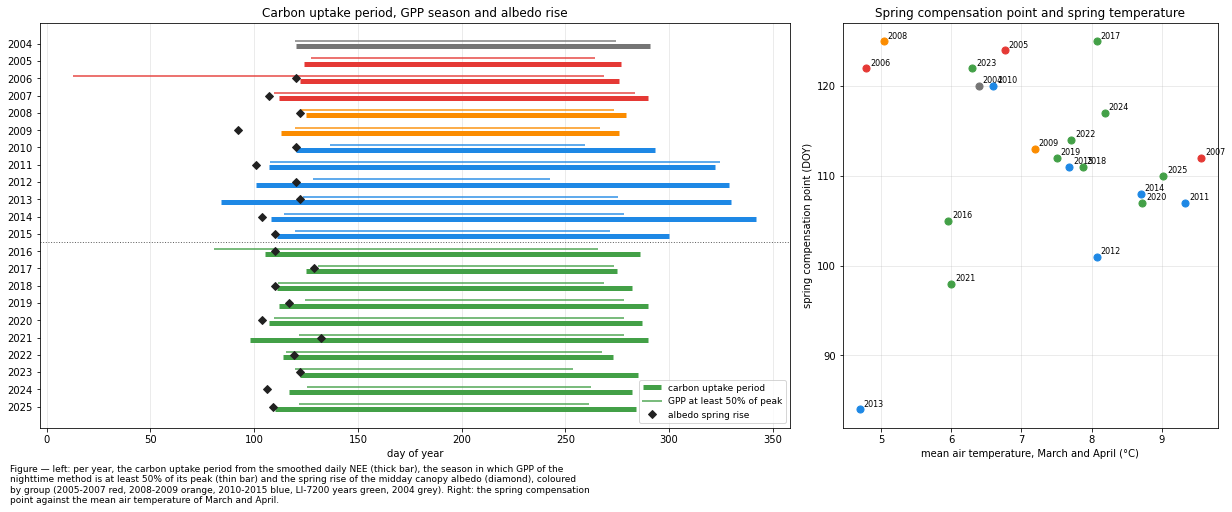

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(17, 7), dpi=72, layout="constrained", width_ratios=[2, 1])
_ax = axs[0]
for _y, _r in pheno.iterrows():
    _col = COLORS.get(group_of(_y), '#757575')
    _ax.plot([_r['NEE negative from (DOY)'], _r['NEE negative to (DOY)']], [_y + 0.15] * 2, color=_col, lw=5,
             solid_capstyle='butt', label='carbon uptake period' if _y == 2016 else None)
    _ax.plot([_r['GPP NT high from (DOY)'], _r['GPP NT high to (DOY)']], [_y - 0.15] * 2, color=_col, lw=2,
             alpha=0.7, label=f'GPP at least {GPP_FRACTION:.0%} of peak' if _y == 2016 else None)
    _ax.plot(_r['albedo spring rise (DOY)'], _y, marker='D', color='#212121', ms=6, ls='none',
             label='albedo spring rise' if _y == 2016 else None)
_ax.axhline(2015.5, color='#616161', lw=1, ls=':')
_ax.invert_yaxis()
_ax.set_yticks(pheno.index)
_ax.set_xlabel("day of year")
_ax.set_title("Carbon uptake period, GPP season and albedo rise")
_ax.grid(alpha=0.3, axis='x')
_ax.legend(fontsize=9, loc='lower right')
_ax = axs[1]
for _y, _r in pheno.iterrows():
    _col = COLORS.get(group_of(_y), '#757575')
    _ax.scatter(_r['TA Mar-Apr (°C)'], _r['NEE negative from (DOY)'], color=_col, s=50, zorder=3)
    _ax.annotate(str(_y), (_r['TA Mar-Apr (°C)'], _r['NEE negative from (DOY)']), fontsize=8,
                 xytext=(4, 3), textcoords='offset points')
_ax.set_xlabel("mean air temperature, March and April (°C)")
_ax.set_ylabel("spring compensation point (DOY)")
_ax.set_title("Spring compensation point and spring temperature")
_ax.grid(alpha=0.3)
figcap(fig, "left: per year, the carbon uptake period from the smoothed daily NEE (thick bar), the "
            f"season in which GPP of the nighttime method is at least {GPP_FRACTION:.0%} of its peak (thin "
            "bar) and the spring rise of the midday canopy albedo (diamond), coloured by group (2005-2007 "
            "red, 2008-2009 orange, 2010-2015 blue, LI-7200 years green, 2004 grey). Right: the spring "
            "compensation point against the mean air temperature of March and April.")
fig.show()

The carbon uptake period of 2005-2009 starts later and ends earlier than in the LI-7200 years, by
about one standard deviation of those years in total; that of 2010-2015 is longer. The spring rise
of the albedo and the rise of `GPP` to half its peak are not later in the early years. The later
spring compensation point therefore reflects a smaller net uptake in spring, consistent with the
lower `GPP` of April, rather than a later leaf-out. The spring compensation point is earlier after
warmer springs; at the same spring temperature the early years tend to reach it later than the
other years. The cool springs of 2006 and 2008 contribute to the late dates of 2005-2009.

</br>

# 4 Weather of each year

Per year, the conditions that set `GPP` and `RECO`: air temperature of the year, spring and
summer, the daytime VPD and incoming shortwave radiation of May to September, soil water content
at 0.1 and 0.3 m, and precipitation. The homogenised series are used throughout, so the probe
changes of 2016 (TA, RH), 2018 (precipitation) and 2020 (soil water) do not enter as steps; the
homogenised soil water content is an estimate for continuity rather than an absolute value. The
meteo data start in 2004, so the drought summer of 2003 cannot be characterised from them.

In [36]:
_sm = F[F['month'].isin(SUMMER)]
_smd = _sm[_sm['day']]
weather = pd.DataFrame({
    'TA year (°C)': F.groupby('year')['ta'].mean(),
    'TA Mar-May (°C)': F[F['month'].isin([3, 4, 5])].groupby('year')['ta'].mean(),
    'TA May-Sep (°C)': _sm.groupby('year')['ta'].mean(),
    'VPD May-Sep, day (kPa)': _smd.groupby('year')['vpd'].mean(),
    'SW_IN May-Sep (MJ m-2)': _sm.groupby('year')['sw'].sum() * 1800 / 1e6,
    'SW_IN May-Sep measured (%)': _sm.groupby('year')['sw_meas'].mean() * 100,
    'SWC 0.1 m May-Sep (%)': _sm.groupby('year')['swc10'].mean(),
    'SWC 0.1 m May-Sep, min of days (%)': _sm['swc10'].resample('D').mean().groupby(
        lambda t: t.year).min(),
    'SWC 0.3 m May-Sep (%)': _sm.groupby('year')['swc30'].mean(),
    'SWC May-Sep covered (%)': _sm.groupby('year')['swc10'].count() / _sm.groupby('year').size() * 100,
    'PREC year (mm)': F.groupby('year')['prec'].sum(min_count=1),
    'PREC May-Sep (mm)': _sm.groupby('year')['prec'].sum(min_count=1),
})
weather.index.name = 'YEAR'

## 📋 Table: weather per year

In [37]:
_fmt = {c: "{:.1f}" for c in weather.columns}
_fmt.update({'VPD May-Sep, day (kPa)': "{:.2f}", 'SW_IN May-Sep (MJ m-2)': "{:,.0f}", 'PREC year (mm)': "{:,.0f}",
             'PREC May-Sep (mm)': "{:,.0f}", 'SW_IN May-Sep measured (%)': "{:.0f}", 'SWC May-Sep covered (%)': "{:.0f}"})
display(styled(weather, caption="per year, the mean air temperature of the year, of March to May and of May to "
                                "September; the mean daytime VPD and the sum of SW_IN of May to September, with "
                                "the share of measured SW_IN (the rest is gap-filled); the mean and the lowest "
                                "daily soil water content at 0.1 m and the mean at 0.3 m over May to September, "
                                "with the share of half-hours with a value at 0.1 m; and precipitation of the "
                                "year and of May to September", fmt=_fmt, cmap=None))

Table — per year, the mean air temperature of the year, of March to May and of May to September; the
mean daytime VPD and the sum of SW_IN of May to September, with the share of measured SW_IN (the
rest is gap-filled); the mean and the lowest daily soil water content at 0.1 m and the mean at 0.3 m
over May to September, with the share of half-hours with a value at 0.1 m; and precipitation of the
year and of May to September



,TA year (°C),TA Mar-May (°C),TA May-Sep (°C),"VPD May-Sep, day (kPa)",SW_IN May-Sep (MJ m-2),SW_IN May-Sep measured (%),SWC 0.1 m May-Sep (%),"SWC 0.1 m May-Sep, min of days (%)",SWC 0.3 m May-Sep (%),SWC May-Sep covered (%),PREC year (mm),PREC May-Sep (mm)
YEAR,,,,,,,,,,,,
2004,8.8,8.1,15.5,0.60,"2,827",0,21.2,13.8,18.5,15,"1,063",558
2005,8.7,8.9,16.0,0.62,"2,826",11,23.2,18.2,22.7,100,835,467
2006,9.3,7.3,16.5,0.65,"2,766",100,24.3,16.8,22.7,96,"1,222",578
2007,9.4,11.0,15.2,0.52,"2,662",100,27.4,21.7,24.9,100,"1,100",773
2008,8.9,8.3,15.5,0.55,"2,803",100,27.6,20.4,25.2,100,"1,008",459
2009,9.3,9.8,16.6,0.60,"2,928",93,26.0,20.6,23.3,73,932,480
2010,8.1,7.9,15.2,0.54,"2,609",98,28.4,18.3,26.6,82,"1,072",691
2011,10.1,11.3,16.4,0.66,"2,968",100,27.1,21.4,24.8,100,744,456
2012,9.1,9.9,16.1,0.57,"2,885",91,30.5,23.4,26.1,97,"1,154",628


## 📋 Table: weather per year relative to the LI-7200 years

In [38]:
_cols = ['TA year (°C)', 'TA Mar-May (°C)', 'TA May-Sep (°C)', 'VPD May-Sep, day (kPa)', 'SW_IN May-Sep (MJ m-2)',
         'SWC 0.1 m May-Sep (%)', 'SWC 0.1 m May-Sep, min of days (%)', 'SWC 0.3 m May-Sep (%)', 'PREC year (mm)',
         'PREC May-Sep (mm)']
_r = weather.loc[IRGA72_YEARS[0]:IRGA72_YEARS[1], _cols]
weather_z = (weather[_cols] - _r.mean()) / _r.std()
weather_z.columns = [c.split(' (')[0] for c in _cols]
display(styled(weather_z, caption=f"per year, each weather variable as its difference to the mean of the LI-7200 "
                                  f"years {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, in standard deviations of those "
                                  f"years. Red: warmer, drier air, more radiation, wetter soil or more rain than "
                                  f"the LI-7200 mean; blue: the opposite", fmt="{:.1f}"))

Table — per year, each weather variable as its difference to the mean of the LI-7200 years
2016-2025, in standard deviations of those years. Red: warmer, drier air, more radiation, wetter
soil or more rain than the LI-7200 mean; blue: the opposite



,TA year,TA Mar-May,TA May-Sep,"VPD May-Sep, day",SW_IN May-Sep,SWC 0.1 m May-Sep,"SWC 0.1 m May-Sep, min of days",SWC 0.3 m May-Sep,PREC year,PREC May-Sep
YEAR,,,,,,,,,,
2004,-2.0,-1.0,-1.8,-0.8,-1.2,-1.6,-3.0,-3.7,0.6,0.4
2005,-2.2,-0.3,-1.2,-0.6,-1.2,-0.9,-0.7,-1.1,-1.4,-0.7
2006,-1.3,-1.7,-0.5,-0.3,-1.7,-0.5,-1.5,-1.1,1.9,0.6
2007,-1.1,1.4,-2.2,-1.5,-2.4,0.6,1.1,0.2,0.9,2.8
2008,-1.9,-0.8,-1.8,-1.2,-1.4,0.6,0.4,0.4,0.1,-0.8
2009,-1.3,0.4,-0.4,-0.8,-0.5,0.1,0.5,-0.7,-0.6,-0.5
2010,-3.2,-1.2,-2.2,-1.3,-2.7,0.9,-0.7,1.3,0.6,1.9
2011,0.0,1.7,-0.6,-0.2,-0.2,0.5,0.9,0.2,-2.2,-0.8
2012,-1.7,0.5,-1.1,-1.1,-0.8,1.6,2.0,1.0,1.4,1.2


Compared with the LI-7200 years, 2004-2010 were cooler, with lower summer VPD and less summer
radiation; 2013 and 2014 had similar summers. The summer soils of 2004-2006 were drier than the
LI-7200 mean and those of 2007-2014 mostly wetter; 2004 has soil data for only part of its
summer. None of the early years was as warm and dry as the LI-7200 summers 2018 and 2022.

## 📊 Plot: May-September NEE and GPP against the weather of the same months

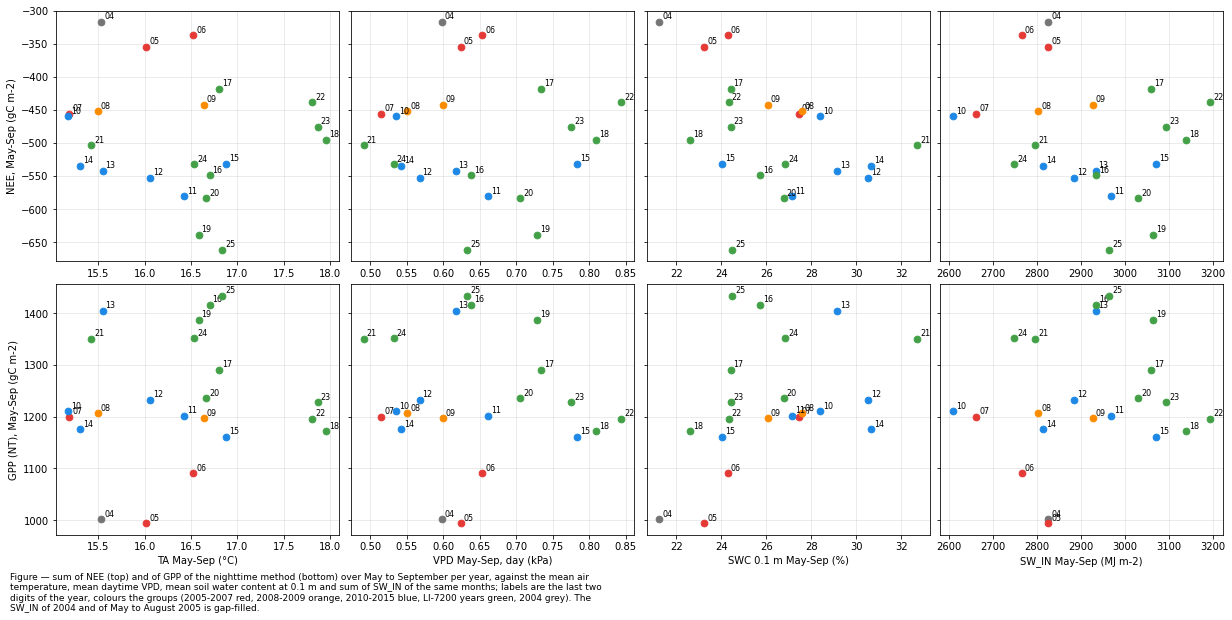

In [39]:
_seas = monthly_y[['nee', 'gpp_nt']].loc[(slice(None), SUMMER), :].groupby('year').sum()
_vars = ['TA May-Sep (°C)', 'VPD May-Sep, day (kPa)', 'SWC 0.1 m May-Sep (%)', 'SW_IN May-Sep (MJ m-2)']
fig, axs = plt.subplots(2, 4, figsize=(17, 8.5), dpi=72, layout="constrained", sharey='row')
for _i, (_c, _lab) in enumerate((('nee', 'NEE'), ('gpp_nt', 'GPP (NT)'))):
    for _j, _v in enumerate(_vars):
        _ax = axs[_i, _j]
        for _y in _seas.index:
            _col = COLORS.get(group_of(_y), '#757575')
            _ax.scatter(weather.loc[_y, _v], _seas.loc[_y, _c], color=_col, s=45, zorder=3)
            _ax.annotate(str(_y)[2:], (weather.loc[_y, _v], _seas.loc[_y, _c]), fontsize=8, xytext=(3, 3),
                         textcoords='offset points')
        _ax.grid(alpha=0.3)
        if _i == 1:
            _ax.set_xlabel(_v)
        if _j == 0:
            _ax.set_ylabel(f"{_lab}, May-Sep ({units_sum})")
figcap(fig, "sum of NEE (top) and of GPP of the nighttime method (bottom) over May to September per year, "
            "against the mean air temperature, mean daytime VPD, mean soil water content at 0.1 m and sum "
            "of SW_IN of the same months; labels are the last two digits of the year, colours the groups "
            "(2005-2007 red, 2008-2009 orange, 2010-2015 blue, LI-7200 years green, 2004 grey). The SW_IN "
            "of 2004 and of May to August 2005 is gap-filled.")
fig.show()

Against the weather of the same months, the May-September `GPP` of 2004, 2005 and 2006 is lower
than in any other year, including the warm, dry LI-7200 summers 2018 and 2022 and the cool, dim
LI-7500 summers 2010, 2013 and 2014. 2007-2009 lie within the spread of the other years. No single
weather variable separates the early years from the rest.

</br>

# 5 Summary: where the difference of the early years sits

## 📋 Table: difference in NEE to the LI-7200 years by season, day and night, and component

In [40]:
_season_y = {s: monthly_y.loc[(slice(None), m), :].groupby('year').sum(min_count=1) for s, m in SEASONS.items()}
_season_y['year'] = sum(_season_y[s] for s in SEASONS)
_ref_yrs = years_of(REF)


def season_diff(season, col, years, ref_years):
    """Mean seasonal sum of `col` over `years` minus that over `ref_years` (gC m-2)."""
    t = _season_y[season][col]
    return t.reindex(years).mean() - t.reindex(ref_years).mean()


def season_table(groups, ref_years):
    """ΔNEE of each group and season against `ref_years`, split into its parts (gC m-2)."""
    rows = {}
    ref_dt = [y for y in ref_years if y in DT_YEARS]
    for g in groups:
        yrs = years_of(g)
        dty = [y for y in yrs if y in DT_YEARS]
        for s in [*SEASONS, 'year']:
            rows[(g, s)] = {
                'ΔNEE': season_diff(s, 'nee', yrs, ref_years),
                'ΔNEE, day': season_diff(s, 'nee_day', yrs, ref_years),
                'ΔNEE, night': season_diff(s, 'nee_night', yrs, ref_years),
                'NT: −ΔGPP': -season_diff(s, 'gpp_nt', yrs, ref_years),
                'NT: ΔRECO': season_diff(s, 'reco_nt', yrs, ref_years),
                'DT years': f"{dty[0]}-{dty[-1]}",
                'ΔNEE, DT years': season_diff(s, 'nee', dty, ref_dt),
                'DT: −ΔGPP': -season_diff(s, 'gpp_dt', dty, ref_dt),
                'DT: ΔRECO': season_diff(s, 'reco_dt', dty, ref_dt),
                'DT: Δrest': season_diff(s, 'dt_rest', dty, ref_dt),
            }
    out = pd.DataFrame(rows).T
    out.index.names = ['group', 'season']
    num = [c for c in out.columns if c != 'DT years']
    out[num] = out[num].astype(float)
    return out


summary = season_table(SUMMARY_GROUPS, _ref_yrs)
_num = [c for c in summary.columns if c != 'DT years']
display(styled(summary, caption=f"per group of LI-7500 years and season, the mean difference to the LI-7200 years "
                                f"{IRGA72_YEARS[0]}-{IRGA72_YEARS[1]} in {units_sum}, as contributions to ΔNEE: "
                                f"split into the daytime and nighttime half-hours (flag DAYTIME), into GPP and "
                                f"RECO of the nighttime method (NT), and into GPP, RECO and the rest of the "
                                f"daytime method (DT), over the complete years of the daytime method. Seasons are "
                                f"sums of calendar months of the same year (Nov-Mar: January to March and "
                                f"November to December). Positive: less uptake than the LI-7200 years",
               subset=_num))

Table — per group of LI-7500 years and season, the mean difference to the LI-7200 years 2016-2025 in
gC m-2, as contributions to ΔNEE: split into the daytime and nighttime half-hours (flag DAYTIME),
into GPP and RECO of the nighttime method (NT), and into GPP, RECO and the rest of the daytime
method (DT), over the complete years of the daytime method. Seasons are sums of calendar months of
the same year (Nov-Mar: January to March and November to December). Positive: less uptake than the
LI-7200 years



Against the LI-7200 years, the deficit of 2005-2009 lies in the daytime half-hours of every
season and mostly in May to September. The nighttime method attributes it to `GPP`; the daytime
method to a larger loss of `GPP`, partly offset by lower `RECO`. 2010-2015 differ from the LI-7200
years in the parts of the daytime method, not in `NEE`.

## 📋 Table: difference in NEE to the LI-7500 years 2010-2015 by season, day and night, and component

The LI-7500 years 2010-2015 have the same analyser, the same correction and an `NEE` close to that
of the LI-7200 years. Against them, the difference of the early years is free of any offset that
the change of analyser brings into the partitioning.

In [41]:
summary_75 = season_table(['2005-2007', '2008-2009', '2005-2009'], years_of('2010-2015'))
display(styled(summary_75, caption=f"as the table above, but against the LI-7500 years 2010-2015 instead of the "
                                   f"LI-7200 years, in {units_sum}. Positive: less uptake than in 2010-2015",
               subset=_num))

Table — as the table above, but against the LI-7500 years 2010-2015 instead of the LI-7200 years, in
gC m-2. Positive: less uptake than in 2010-2015



Within the LI-7500 record the pattern is the same: the early years have less daytime uptake than
2010-2015 in every season, and in 2008-2009 more than half of it falls outside May to September.
The nighttime method attributes it mostly to `GPP`; the daytime method, free of the offset between
the analysers here, splits it about evenly between lower `GPP` and higher `RECO`.

</br>

# End of notebook

In [42]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Finished. {dt_string}")

Finished. 2026-10-31 17:30:40
